# Project on Tomographic Reconstruction

In [1]:
import odl
import numpy as np
import matplotlib.pyplot as plt

from odl.applications import tomo
from odl.contrib.tomo import elekta_icon_geometry

## Preamble

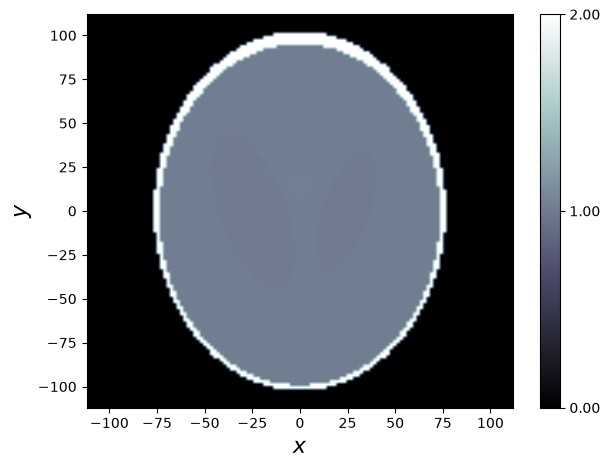

<Figure size 640x480 with 0 Axes>

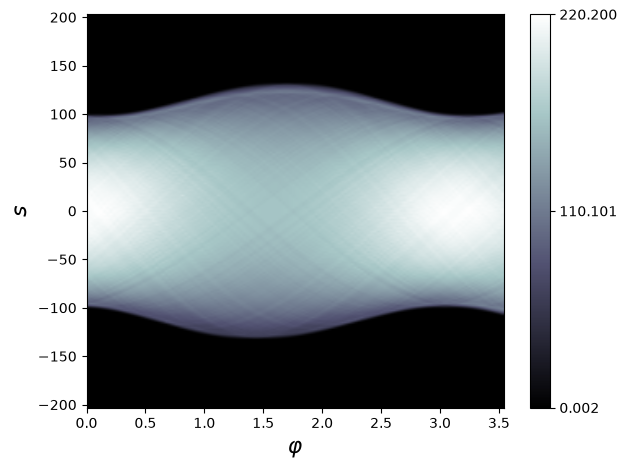

<Figure size 640x480 with 0 Axes>

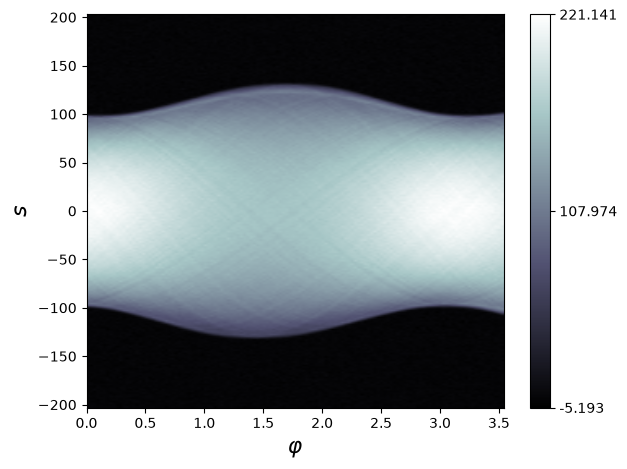

<Figure size 640x480 with 0 Axes>

In [2]:
#space = odl.uniform_discr([-16, -16, -16],[16, 16, 16],(32, 32, 32), dtype='float32')
space = odl.uniform_discr([-112, -112],[112, 112],(128, 128), dtype='float32') #test 2d
phantom = odl.phantom.transmission.shepp_logan(space, modified=False)
phantom.show()

geometry = odl.applications.tomo.cone_beam_geometry(space, src_radius=780.0, det_radius=220.0, num_angles = 128, short_scan=True)
forward = odl.applications.tomo.RayTransform(space, geometry)

# Set the noise so that the relative noise has a norm of approximately 1%
noise = odl.core.phantom.noise.white_noise(forward.range)
exact_data = forward(phantom)
data = (exact_data + (0.01 * exact_data.norm() * noise / noise.norm()))
forward(phantom).show()
data.show()
print("")

## Step 1 - Solving the regularized problem

### Step 1.a - Preliminary tests

In [3]:
l = 1
epsilon = 1/10**3
l2 = odl.functionals.L2NormSquared(forward.range)
data_fit = l2.translated(data)

grad = odl.Gradient(space)
Heps = odl.functionals.Huber(grad.range, epsilon)

regularization = l * Heps * grad

f = 0.5* data_fit*forward + regularization

In [4]:
# Create the linesearch object
line_search = odl.solvers.BacktrackingLineSearch(f, alpha =1, max_num_iter=1000)

# Call the solver
starting_point = space.zero()
odl.solvers.steepest_descent(f, starting_point, maxiter=3000, tol=3, line_search=line_search)
# I used a really big tolerance because I had some imprecision errors because of the float32

In [5]:
# Evaluating the new functional in the random point.
print("f(point) =", f(starting_point))
print("||gradient|| =", f.gradient(starting_point).norm())

f(point) = 2813.3602294921875
||gradient|| = 1.7009042501449585


### Step 1.b - Proper formalisation of the entire script

In [6]:
def solving_regularized_problem(space, forward, data, l, epsilon, alpha, tolerance, k):

    l2 = odl.functionals.L2NormSquared(forward.range)
    data_fit = l2.translated(data)
    
    grad = odl.Gradient(space)
    Heps = odl.functionals.Huber(grad.range, epsilon)
    
    regularization = l * Heps * grad
    
    f = 0.5* data_fit*forward + regularization
    x = space.zero()

    # Evaluating the new functional in starting point.
    print("f(point) =", f(x))
    print("||gradient|| =", f.gradient(x).norm())

    # Create the linesearch object
    line_search = odl.solvers.BacktrackingLineSearch(f, alpha =alpha, max_num_iter=k)
    
    # Call the solver
    odl.solvers.steepest_descent(f, x, maxiter=k, tol=tolerance, line_search=line_search)

    # Evaluating the new functional in the point achieved.
    print("f(point) =", f(x))
    print("||gradient|| =", f.gradient(x).norm())

    print("Naive reconstitution :")
    forward.adjoint(data).show()
    print("Reconstitution :")
    x.show()    
    return x

## Step 2 - Test of the script in 2D

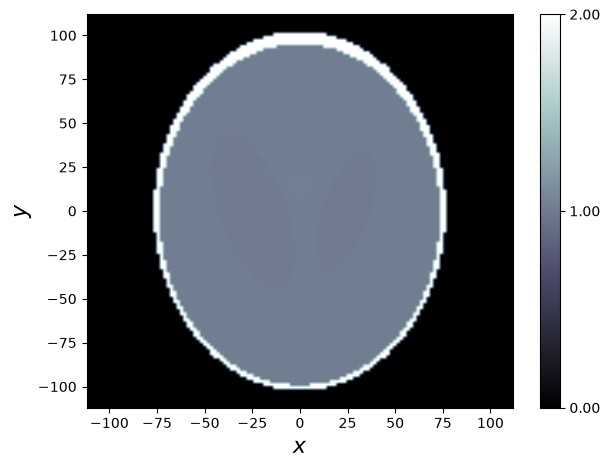

<Figure size 640x480 with 0 Axes>

f(point) = 10094641.0
||gradient|| = 135251.07421875
f(point) = 2810.3829345703125
||gradient|| = 2.019713282585144
Naive reconstitution :


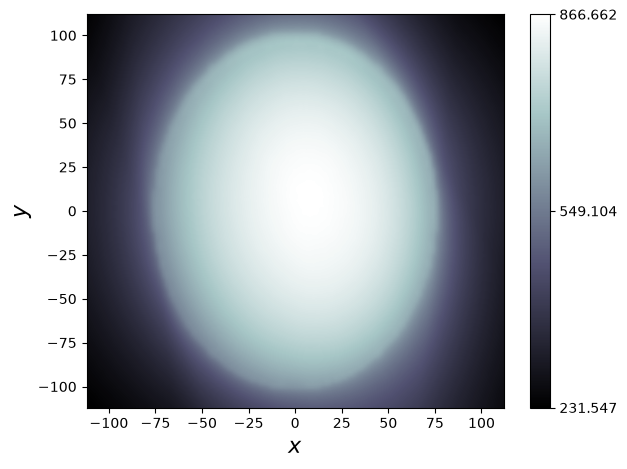

<Figure size 640x480 with 0 Axes>

Reconstitution :


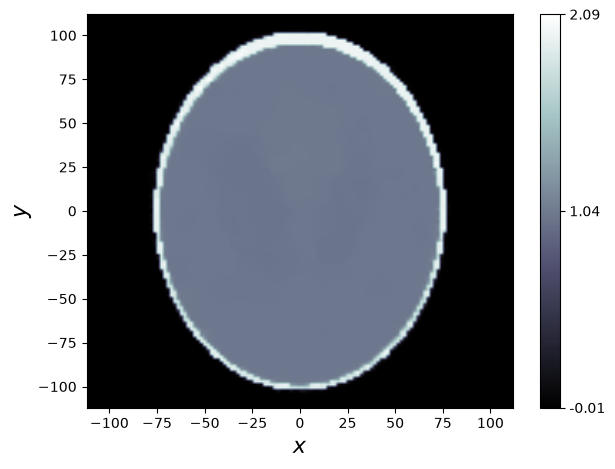

<Figure size 640x480 with 0 Axes>

In [7]:
# Set the noise so that the relative noise has a norm of approximately noise_level
noise = odl.core.phantom.noise.white_noise(forward.range)
exact_data = forward(phantom)
data = (exact_data + (0.01 * exact_data.norm() * noise / noise.norm()))

phantom.show() # for comparison
solving_regularized_problem(space, forward, data, 1, 1/10**3, 1, 5, 3000)
print("")

## Step 3 - Choice of the epsilon parameter

I wanted to test different combinations of lambda and epsilon in order to study their impact on the reconstruction. Some combinations caused the solver to fail after a lot of iterations (because of the use of float32), so I used a "try block" to handle these cases and continue the tests. I tested multiple k and tolerance as I wanted to go at the maximum iterations available to have the most optimized reconstruction possible for each combination.

For each combination, I evaluated both the final gradient and the reconstructed image. This was useful because a lower gradient did not always correspond to a better reconstruction: in some cases, the reconstructed image contained more noise or was less suitable for interpretation despite having a relatively low final gradient.

I also displayed the exact solution and the naive reconstruction to provide reference points and make the comparison between the different results more efficient.

In [8]:
def benchmark_epsilon_lambda(space, data, tolerance, k):

    lambdas = np.array([100,1,1/100,1/10**4])
    epsilons = np.array([10,1/10,1/1000,1/10**5])

    #The following values (commented out) were the ones I used for my personal tests.
    # I kept the ones before so that the code could be executed quicker.
    #lambdas = np.array([100,10,1,1/10,1/100,1/1000,1/10**4,1/10**5])
    #epsilons = np.array([100,10,1,1/10,1/100,1/1000,1/10**4,1/10**5])

    print("Exact data :")
    phantom.show()

    print("Naive reconstitution :")
    forward.adjoint(data).show()

    for l in lambdas :
        for epsilon in epsilons :
            # Construction of the objective functional
            l2 = odl.functionals.L2NormSquared(forward.range)
            data_fit = l2.translated(data)
            
            grad = odl.Gradient(space)
            Heps = odl.functionals.Huber(grad.range, epsilon)
            
            regularization = l * Heps * grad
            
            f = 0.5* data_fit*forward + regularization
    
            # Finding the minimum of f
            # Create the linesearch object
            line_search = odl.solvers.BacktrackingLineSearch(f, alpha = 1, max_num_iter=k)
            
            # Call the solver
            x = space.zero()
    
            print("----- For lambda =", l,"and epsilon =", epsilon,":")

            # Evaluating the new functional in starting point.
            print("f(x) =",f(x))
            print("||gradient|| =", f.gradient(x).norm())
    
            try :
                x = space.zero()
                odl.solvers.steepest_descent(f, x, maxiter=k, tol=tolerance, line_search=line_search)
                print("The solver reaches its maximum number of iterations",k," or naturally stop before")
                print("|f(x)|=",f(x),"|grad(f(x))|=",f.gradient(x).norm())
            # I created a try/except block because during my tests I often had AssertionError because the gradient hadn't reached 0 yet however, because of the low resolution of the floats, there were no direction of descent found.
            except :
                print("The solver fails before reaching the max number of iterations",k)
                print("|f(x)|=",f(x),"|grad(f(x))|=",f.gradient(x).norm())
            print("Reconstitution :")
            x.show()
    
    return x

Exact data :


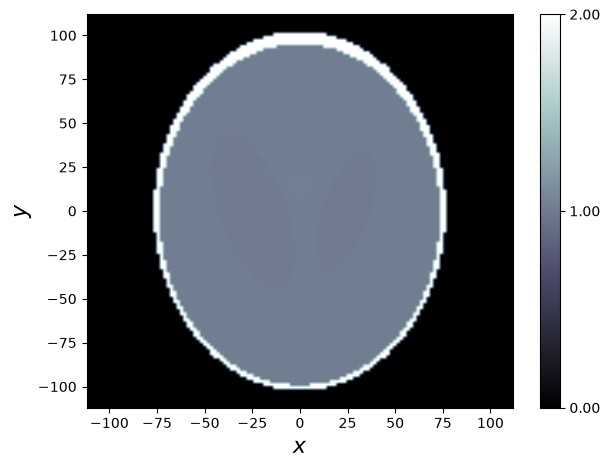

<Figure size 640x480 with 0 Axes>

Naive reconstitution :


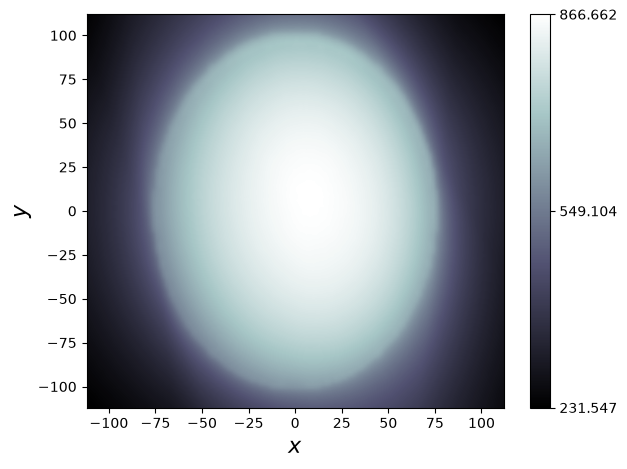

<Figure size 640x480 with 0 Axes>

----- For lambda = 100.0 and epsilon = 10.0 :
f(x) = 10094641.0
||gradient|| = 135251.07421875
The solver reaches its maximum number of iterations 3000  or naturally stop before
|f(x)|= 5031.125198364258 |grad(f(x))|= 9.470987796783447
Reconstitution :


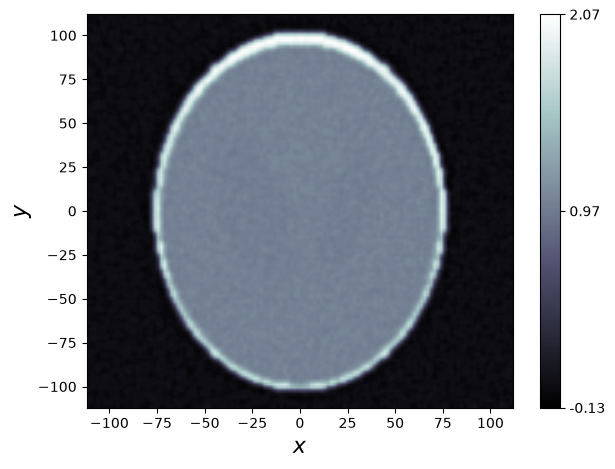

<Figure size 640x480 with 0 Axes>

----- For lambda = 100.0 and epsilon = 0.1 :
f(x) = 10094641.0
||gradient|| = 135251.07421875
The solver reaches its maximum number of iterations 3000  or naturally stop before
|f(x)|= 50999.141845703125 |grad(f(x))|= 8.37315809726715
Reconstitution :


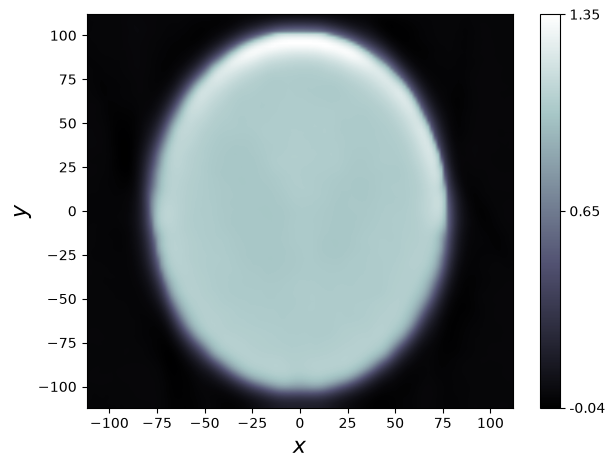

<Figure size 640x480 with 0 Axes>

----- For lambda = 100.0 and epsilon = 0.001 :
f(x) = 10094641.0
||gradient|| = 135251.07421875
The solver reaches its maximum number of iterations 3000  or naturally stop before
|f(x)|= 83615.83374023438 |grad(f(x))|= 787.4069671630859
Reconstitution :


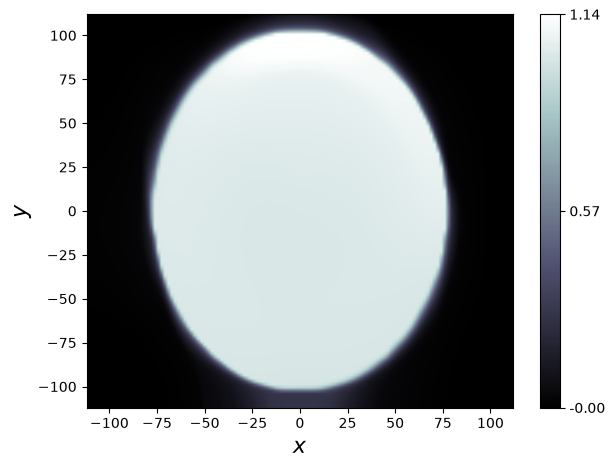

<Figure size 640x480 with 0 Axes>

----- For lambda = 100.0 and epsilon = 1e-05 :
f(x) = 10094641.0
||gradient|| = 135251.07421875
The solver reaches its maximum number of iterations 3000  or naturally stop before
|f(x)|= 98437.29467773438 |grad(f(x))|= 6786.320556640625
Reconstitution :


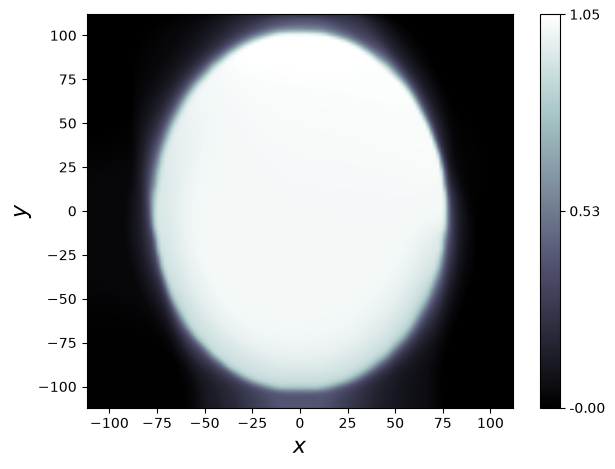

<Figure size 640x480 with 0 Axes>

----- For lambda = 1.0 and epsilon = 10.0 :
f(x) = 10094641.0
||gradient|| = 135251.07421875
The solver reaches its maximum number of iterations 3000  or naturally stop before
|f(x)|= 649.4159774780273 |grad(f(x))|= 9.876110553741455
Reconstitution :


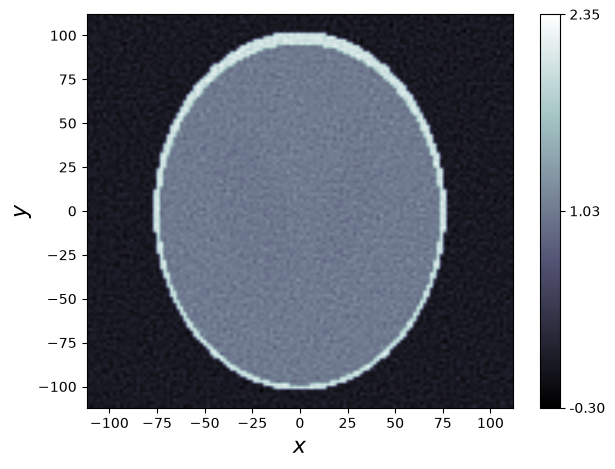

<Figure size 640x480 with 0 Axes>

----- For lambda = 1.0 and epsilon = 0.1 :
f(x) = 10094641.0
||gradient|| = 135251.07421875
The solver reaches its maximum number of iterations 3000  or naturally stop before
|f(x)|= 2488.022705078125 |grad(f(x))|= 9.784314393997192
Reconstitution :


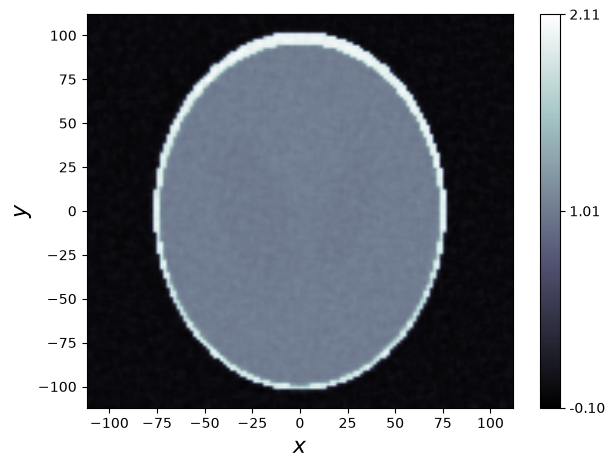

<Figure size 640x480 with 0 Axes>

----- For lambda = 1.0 and epsilon = 0.001 :
f(x) = 10094641.0
||gradient|| = 135251.07421875
The solver reaches its maximum number of iterations 3000  or naturally stop before
|f(x)|= 2817.37939453125 |grad(f(x))|= 9.524235010147095
Reconstitution :


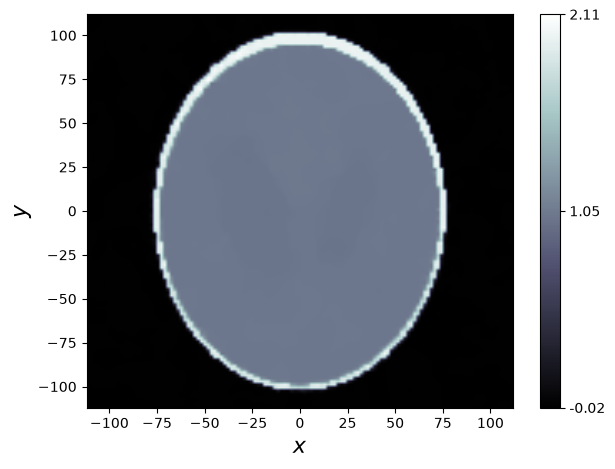

<Figure size 640x480 with 0 Axes>

----- For lambda = 1.0 and epsilon = 1e-05 :
f(x) = 10094641.0
||gradient|| = 135251.07421875
The solver reaches its maximum number of iterations 3000  or naturally stop before
|f(x)|= 2888.7314453125 |grad(f(x))|= 51.039509296417236
Reconstitution :


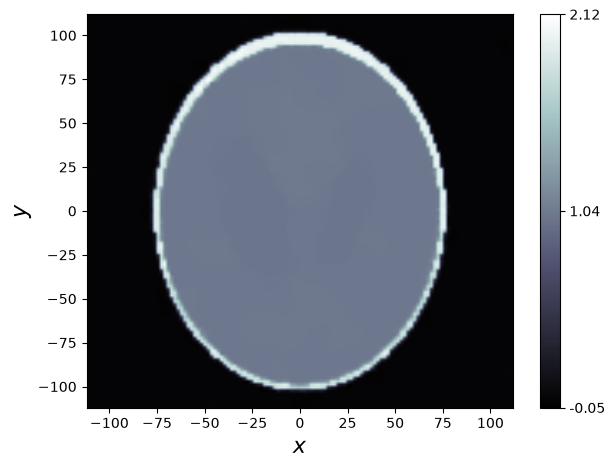

<Figure size 640x480 with 0 Axes>

----- For lambda = 0.01 and epsilon = 10.0 :
f(x) = 10094641.0
||gradient|| = 135251.07421875
The solver reaches its maximum number of iterations 3000  or naturally stop before
|f(x)|= 534.9635890960693 |grad(f(x))|= 9.707046270370483
Reconstitution :


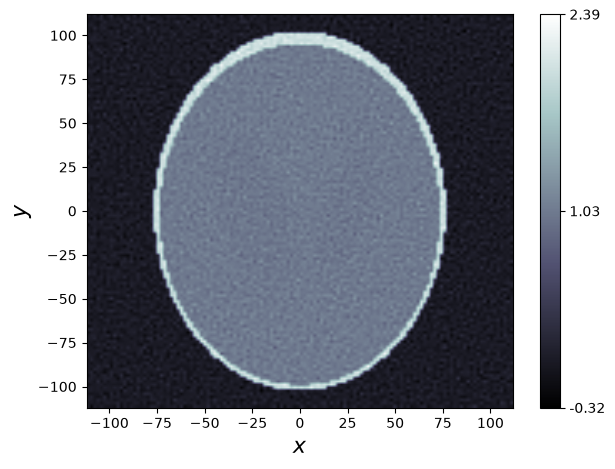

<Figure size 640x480 with 0 Axes>

----- For lambda = 0.01 and epsilon = 0.1 :
f(x) = 10094641.0
||gradient|| = 135251.07421875
The solver reaches its maximum number of iterations 3000  or naturally stop before
|f(x)|= 575.9556665039063 |grad(f(x))|= 9.964174151420593
Reconstitution :


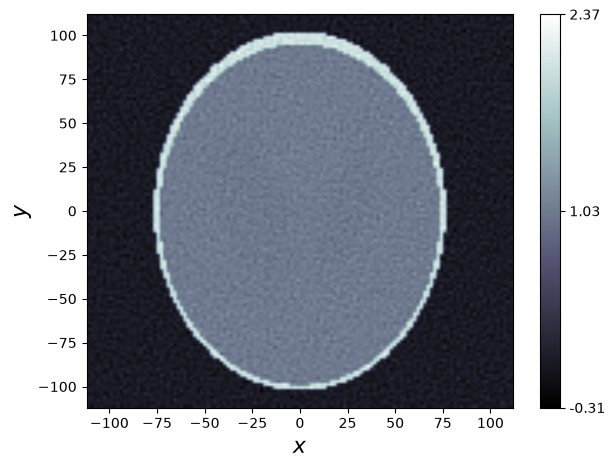

<Figure size 640x480 with 0 Axes>

----- For lambda = 0.01 and epsilon = 0.001 :
f(x) = 10094641.0
||gradient|| = 135251.07421875
The solver reaches its maximum number of iterations 3000  or naturally stop before
|f(x)|= 598.1433642578126 |grad(f(x))|= 9.83210003376007
Reconstitution :


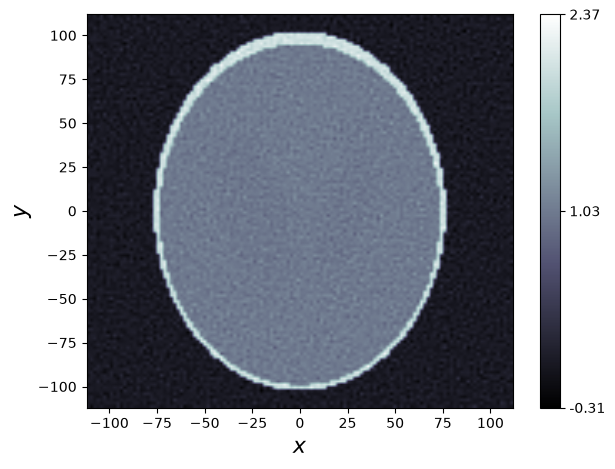

<Figure size 640x480 with 0 Axes>

----- For lambda = 0.01 and epsilon = 1e-05 :
f(x) = 10094641.0
||gradient|| = 135251.07421875
The solver reaches its maximum number of iterations 3000  or naturally stop before
|f(x)|= 598.39169921875 |grad(f(x))|= 9.832125902175903
Reconstitution :


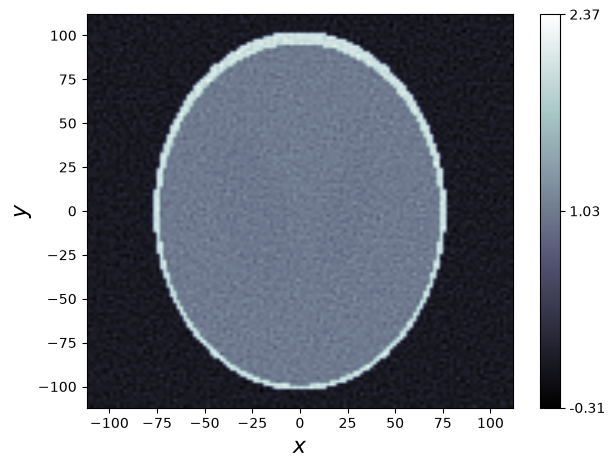

<Figure size 640x480 with 0 Axes>

----- For lambda = 0.0001 and epsilon = 10.0 :
f(x) = 10094641.0
||gradient|| = 135251.07421875
The solver reaches its maximum number of iterations 3000  or naturally stop before
|f(x)|= 533.8326558334351 |grad(f(x))|= 9.719430565834045
Reconstitution :


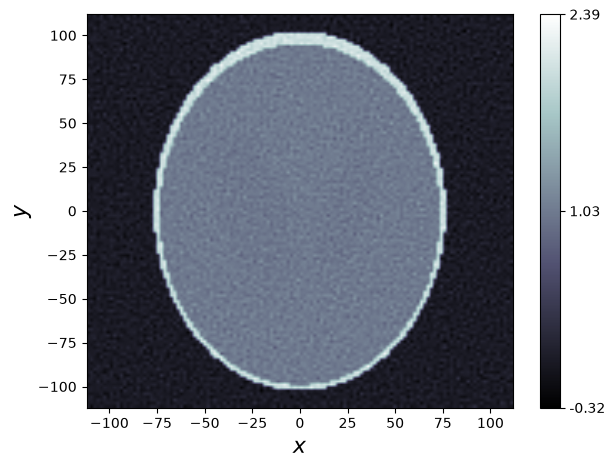

<Figure size 640x480 with 0 Axes>

----- For lambda = 0.0001 and epsilon = 0.1 :
f(x) = 10094641.0
||gradient|| = 135251.07421875
The solver reaches its maximum number of iterations 3000  or naturally stop before
|f(x)|= 534.2324828125 |grad(f(x))|= 9.711905360221863
Reconstitution :


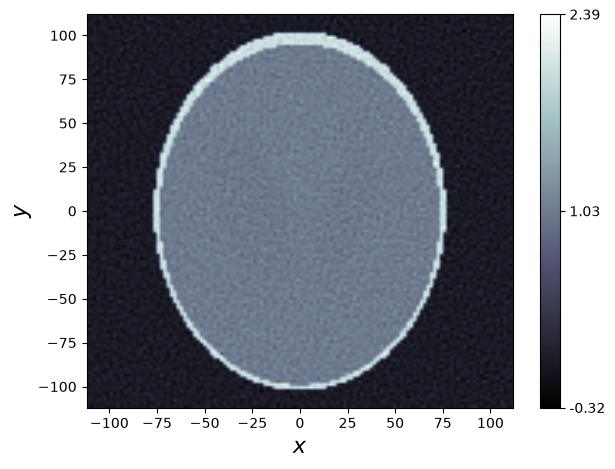

<Figure size 640x480 with 0 Axes>

----- For lambda = 0.0001 and epsilon = 0.001 :
f(x) = 10094641.0
||gradient|| = 135251.07421875
The solver reaches its maximum number of iterations 3000  or naturally stop before
|f(x)|= 534.4501459472656 |grad(f(x))|= 9.711899518966675
Reconstitution :


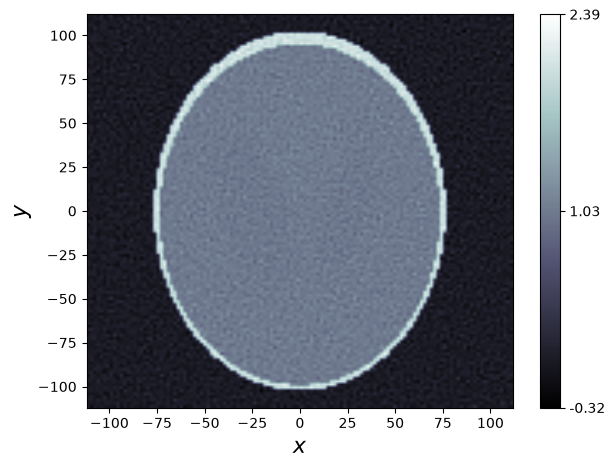

<Figure size 640x480 with 0 Axes>

----- For lambda = 0.0001 and epsilon = 1e-05 :
f(x) = 10094641.0
||gradient|| = 135251.07421875
The solver reaches its maximum number of iterations 3000  or naturally stop before
|f(x)|= 534.4526296386719 |grad(f(x))|= 9.710798025131226
Reconstitution :


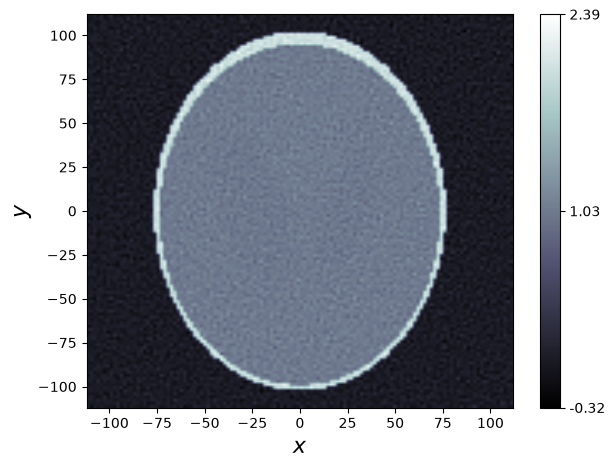

<Figure size 640x480 with 0 Axes>

In [9]:
benchmark_epsilon_lambda(space, data, 100, 3000)
print("")

The result of all of my tests is that epsilon = 0.001 is generally a good value : most of the time it is the first reconstitution without visible noise. The gradient is also relatively good.


On visual criteria, the optimal combination is (lambda = 1.0 and epsilon = 0.001), on my longer test it was better than above. (lambda = 1.0, epsilon = 0.01) and (lambda = 1.0, epsilon = 0.0001) (with more iterations than on the code above) were also really good. For epsilon = 0.01 the reconstitution was a bit noisy and for epsilon = 0.0001 it was a bit too smooth/blurry. I also tried to keep the biggest epsilon that returned a good result given the fact that the smaller epsilon is the smaller the search step must be.

In general, I observed that when lambda decreases, the global noise of the reconstitued image goes up and that when epsilon goes down, it smooth the global image and either reduce the noise or make the reconstructed image a bit blurry

### Step 4.a - Finding the right regularisation parameter

In [10]:
niter = 300       
def benchmark_lambda(space, data, forward, phantom, epsilon, tolerance, k, x1, x2, x3):

    lambdas = np.logspace(x1, x2, x3) #x3 points from 10**x1 to 10**x2
    
    l2 = odl.functionals.L2NormSquared(forward.range)
    data_fit = l2.translated(data)    
    grad = odl.Gradient(space)
    Heps = odl.functionals.Huber(grad.range, epsilon)
    
    residuals_list, penalties_list, errors_list = [], [], []
    x = space.zero()
    for l in lambdas:
        x = space.zero()
        l = float(l)
        regularization = l * Heps * grad
        f = 0.5 * data_fit * forward + regularization
    
        line_search = odl.solvers.BacktrackingLineSearch(f, alpha=1, max_num_iter=k)
        try:
            odl.solvers.steepest_descent(f, x, maxiter=k, line_search=line_search)
        except AssertionError:
            pass
    
        residuals_list.append(float((forward(x) - data).norm()))
        penalties_list.append(float(Heps(grad(x))))
        errors_list.append(float((x - phantom).norm() / phantom.norm()))
        print(f"lambda={l:.1e}  residual={residuals_list[-1]:.3e}  H_eps={penalties_list[-1]:.3e}  error={errors_list[-1]:.4f}")
    
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    
    ax[0].loglog(lambdas, errors_list, 'o-')
    k = int(np.argmin(errors_list))
    ax[0].axvline(lambdas[k], ls='--', c='gray')
    ax[0].set(xlabel=r'$\lambda$', ylabel=r'$\|x_\lambda - x^\dagger\| / \|x^\dagger\|$',
              title='Reconstitution error as a function of lambda')
    
    ax[1].loglog(residuals_list, penalties_list, 'o-')
    for l, r, p in zip(lambdas, residuals_list, penalties_list):
        ax[1].annotate(f'{l:.0e}', (r, p), fontsize=7)
    ax[1].axvline(float((data - exact_data).norm()), ls=':', c='r', label=r'$\delta$')
    ax[1].set(xlabel=r'$\|A x_\lambda - y\|$', ylabel=r'$H_\epsilon(\nabla x_\lambda)$', title='L curve')
    ax[1].legend()
    plt.tight_layout(); plt.show()

lambda=1.0e+01  residual=9.820e+01  H_eps=1.071e+03  error=0.1826
lambda=3.2e+00  residual=6.235e+01  H_eps=1.426e+03  error=0.1167
lambda=1.0e+00  residual=4.726e+01  H_eps=1.718e+03  error=0.0578
lambda=3.2e-01  residual=4.168e+01  H_eps=2.196e+03  error=0.0452
lambda=1.0e-01  residual=3.612e+01  H_eps=3.647e+03  error=0.0696
lambda=3.2e-02  residual=3.442e+01  H_eps=4.684e+03  error=0.0880
lambda=1.0e-02  residual=3.404e+01  H_eps=5.091e+03  error=0.0952
lambda=3.2e-03  residual=3.395e+01  H_eps=5.226e+03  error=0.0976
lambda=1.0e-03  residual=3.392e+01  H_eps=5.270e+03  error=0.0983


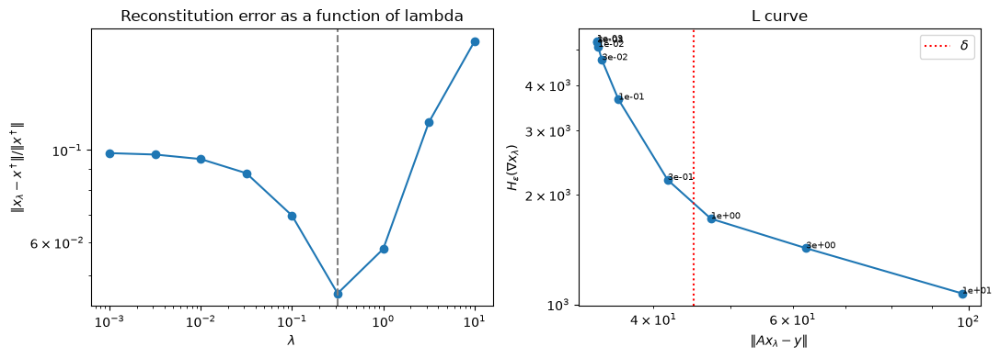

In [11]:
benchmark_lambda(space, data, forward, phantom, 1/10**3, 5, 300, 1, -3, 9)

#### Analysis of the first graph
As observed in the visual reconstructions, the optimal value of lambda is close to 1. In particular, lambda = 1 is the first value for which the error is inferior to 0.1. Although it does not produce the lowest relative error, this value is considered acceptable since it is of the same order as the minimum. The goal being to reduce the reconstruction error (noise error + regularisation error).

#### Analysis of the second graph
Without knowing the real phantom, we see that the "elbow" of the L-curve is between 0.03 and 1. That is coherent with the result observed in the first graph so for the 3D problem we can consider the result of the L-curve as equivalent to the ones of the 1st graph to a certain degree.

For more information, I will rerun the same code below with values closer to the real minimum.

lambda=1.0e+00  residual=4.726e+01  H_eps=1.718e+03  error=0.0578
lambda=7.5e-01  residual=4.589e+01  H_eps=1.777e+03  error=0.0503
lambda=5.6e-01  residual=4.457e+01  H_eps=1.864e+03  error=0.0446
lambda=4.2e-01  residual=4.325e+01  H_eps=1.985e+03  error=0.0432
lambda=3.2e-01  residual=4.168e+01  H_eps=2.196e+03  error=0.0452
lambda=2.4e-01  residual=3.999e+01  H_eps=2.499e+03  error=0.0497
lambda=1.8e-01  residual=3.839e+01  H_eps=2.874e+03  error=0.0560
lambda=1.3e-01  residual=3.709e+01  H_eps=3.270e+03  error=0.0629
lambda=1.0e-01  residual=3.612e+01  H_eps=3.647e+03  error=0.0696


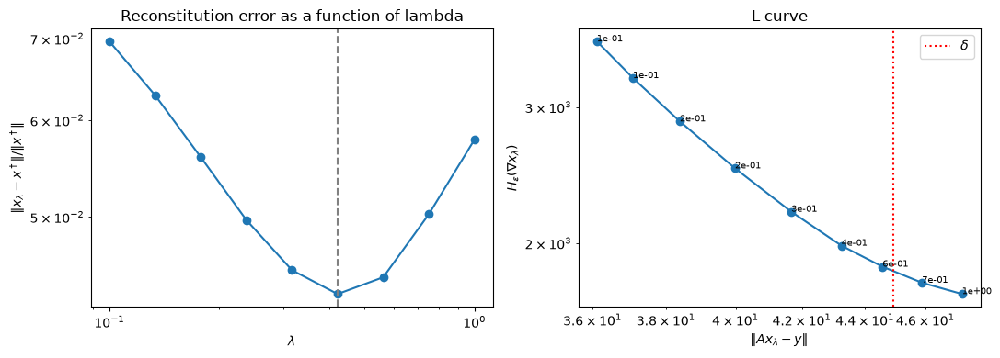

In [12]:
benchmark_lambda(space, data, forward, phantom, 1/10**3, 5, 300, 0, -1, 9)

lambda=4.5e-01  residual=4.359e+01  H_eps=1.949e+03  error=0.0435
lambda=4.4e-01  residual=4.351e+01  H_eps=1.957e+03  error=0.0434
lambda=4.4e-01  residual=4.343e+01  H_eps=1.965e+03  error=0.0432
lambda=4.3e-01  residual=4.335e+01  H_eps=1.973e+03  error=0.0432
lambda=4.2e-01  residual=4.328e+01  H_eps=1.981e+03  error=0.0432
lambda=4.2e-01  residual=4.320e+01  H_eps=1.990e+03  error=0.0432
lambda=4.1e-01  residual=4.313e+01  H_eps=1.998e+03  error=0.0433
lambda=4.1e-01  residual=4.306e+01  H_eps=2.007e+03  error=0.0433
lambda=4.0e-01  residual=4.298e+01  H_eps=2.017e+03  error=0.0433


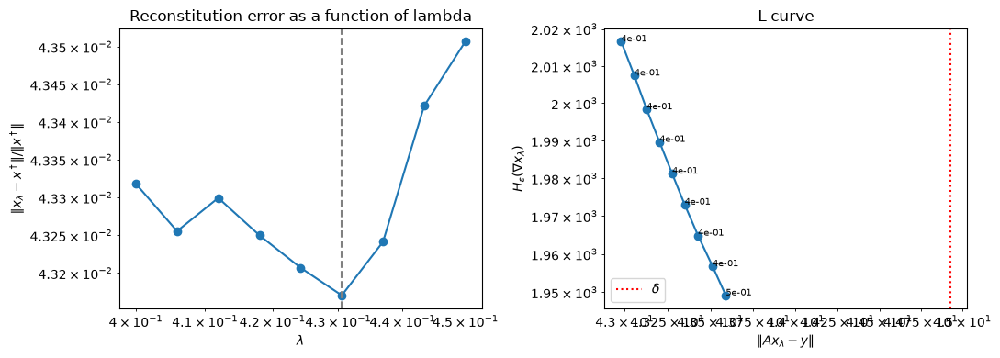

In [13]:
benchmark_lambda(space, data, forward, phantom, 1/10**3, 5, 300, np.log10(0.45), np.log10(0.4), 9)

For the following tests I will make lambda vary between 0.1, 0.5 and 1.

### Step 4.b - 2D reconstruction

In [14]:
def solving_regularized_problem_v2(space, phantom, forward, data, l, epsilon, alpha, tolerance, k):

    l2 = odl.functionals.L2NormSquared(forward.range)
    data_fit = l2.translated(data)
    
    grad = odl.Gradient(space)
    Heps = odl.functionals.Huber(grad.range, epsilon)
    
    regularization = l * Heps * grad
    
    f = 0.5* data_fit*forward + regularization
    x = space.zero()

    # Relative error at each iteration
    errors_iter = [float((x - phantom).norm() / phantom.norm())]
    callback = lambda xk: errors_iter.append(float((xk - phantom).norm() / phantom.norm()))

    # Create the linesearch object
    line_search = odl.solvers.BacktrackingLineSearch(f, alpha =alpha, max_num_iter=k)
    
    # Call the solver
    try :
        odl.solvers.steepest_descent(f, x, maxiter=k, tol=tolerance, line_search=line_search, callback = callback)
    except AssertionError :
        pass

    return x, errors_iter

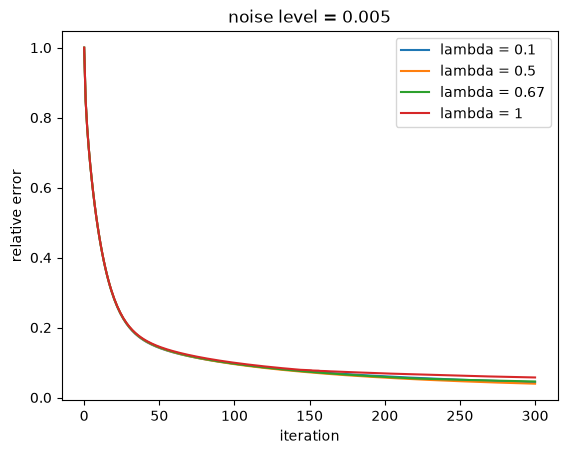

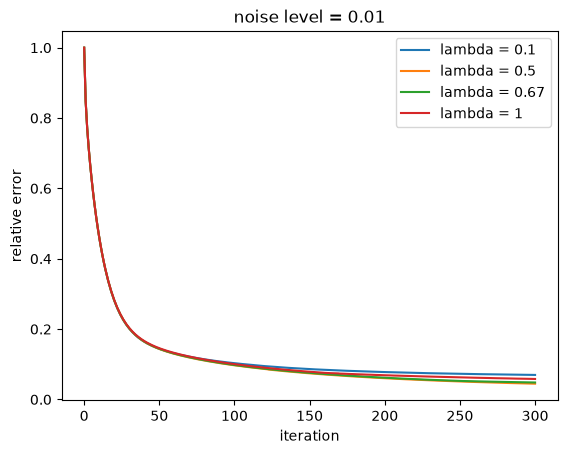

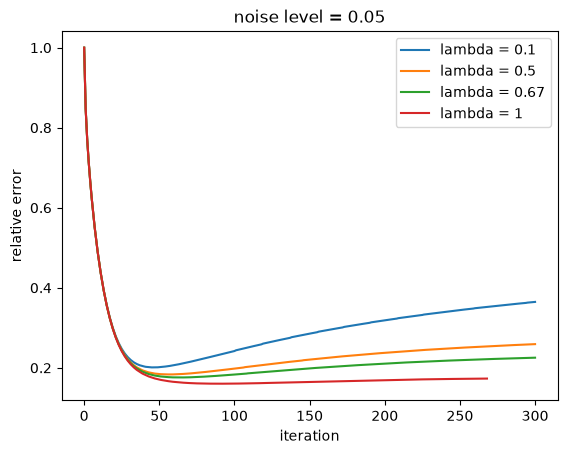

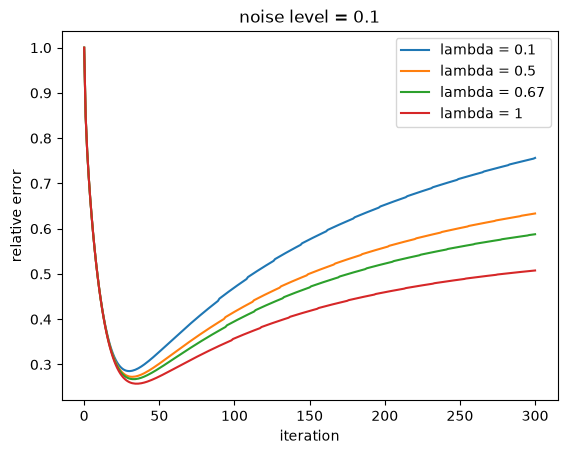

In [15]:
noise_levels = [0.005, 0.01, 0.05, 0.1]
lambdas = [0.1, 0.5, 0.67, 1]

errors = [[] for _ in lambdas]
for noise_level in noise_levels:

    # Set the noise so that the relative noise has a norm of approximately noise_level
    noise = odl.core.phantom.noise.white_noise(forward.range)
    exact_data = forward(phantom)
    data = (exact_data + (noise_level * exact_data.norm() * noise / noise.norm()))
    
    for id_l in range(0, len(lambdas)):

        x, errors_iter = solving_regularized_problem_v2(space, phantom, forward, data, lambdas[id_l], 0.001, 1, 1/10**16, 300)
        errors[id_l].append(errors_iter)

for id_noise in range(0,len(noise_levels)):
    plt.figure()
    for id_l in range(0, len(lambdas)):
        plt.plot(errors[id_l][id_noise], label=f'lambda = {lambdas[id_l]}')
    plt.title(f'noise level = {noise_levels[id_noise]}')
    plt.xlabel('iteration')
    plt.ylabel('relative error')
    plt.legend()
    plt.show()

## Step 5 - 3D reconstruction

### Step 5.a - Test with the 3D Shepp_Logan

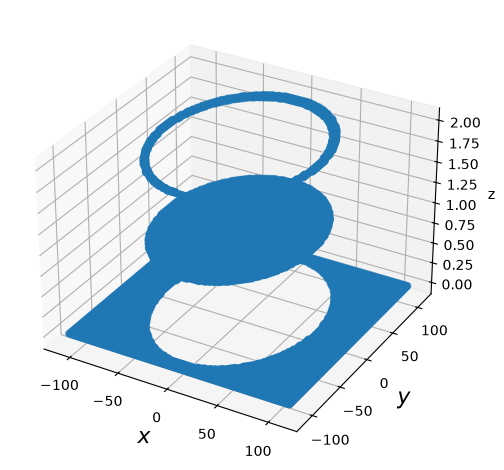

<Figure size 640x480 with 0 Axes>

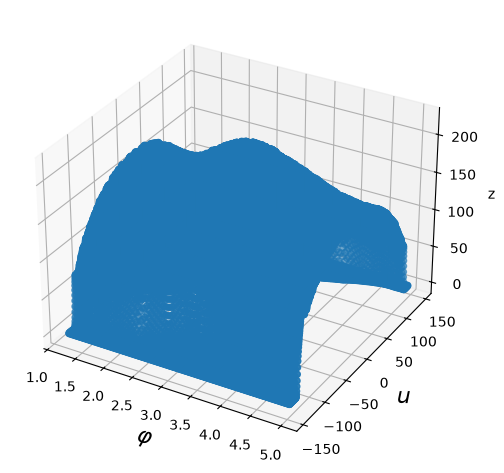

<Figure size 640x480 with 0 Axes>

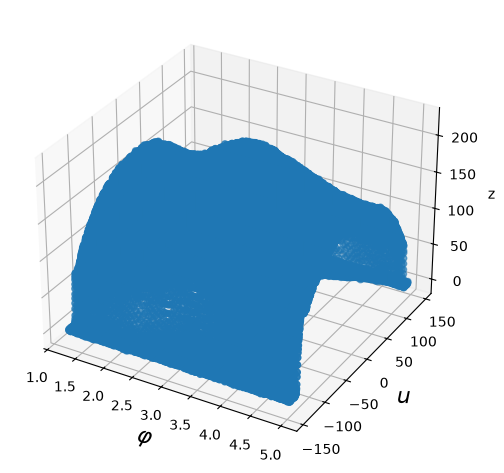

<Figure size 640x480 with 0 Axes>

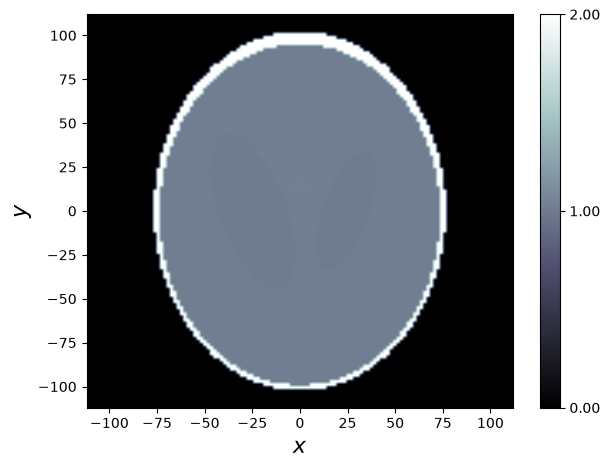

<Figure size 640x480 with 0 Axes>

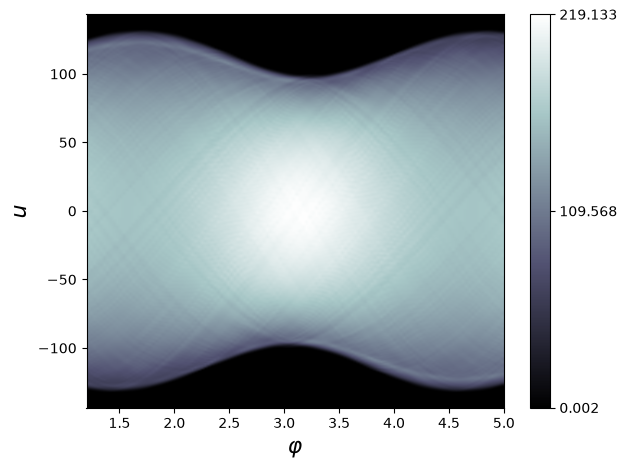

<Figure size 640x480 with 0 Axes>

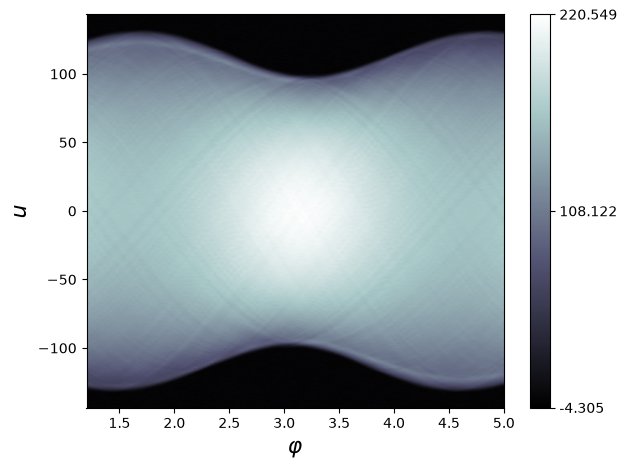

<Figure size 640x480 with 0 Axes>

In [16]:
reco_space = odl.uniform_discr(
[-112, -112, 0],
[112, 112, 224],
(128, 128, 128),
dtype='float32',
)

geometry = elekta_icon_geometry(num_angles=128)

ray_trafo = tomo.RayTransform(
vol_space=reco_space,
geometry=geometry,
)

data_space = ray_trafo.range



phantom3d_shepp_logan = odl.phantom.transmission.shepp_logan(reco_space)

noise = odl.core.phantom.noise.white_noise(data_space)
exact_data3d_shepp_logan = ray_trafo(phantom3d_shepp_logan)

data3d_shepp_logan = (exact_data3d_shepp_logan + (0.01 * exact_data3d_shepp_logan.norm() * noise / noise.norm()))

phantom3d_shepp_logan.show(method="scatter")
ray_trafo(phantom3d_shepp_logan).show(method="scatter")
data3d_shepp_logan.show(method="scatter")


phantom3d_shepp_logan.show()
ray_trafo(phantom3d_shepp_logan).show()
data3d_shepp_logan.show()
print("")

f(point) = 1507883776.0
||gradient|| = 1892806.949695864
f(point) = 897515.28125
||gradient|| = 5453.415448632016
Naive reconstitution :


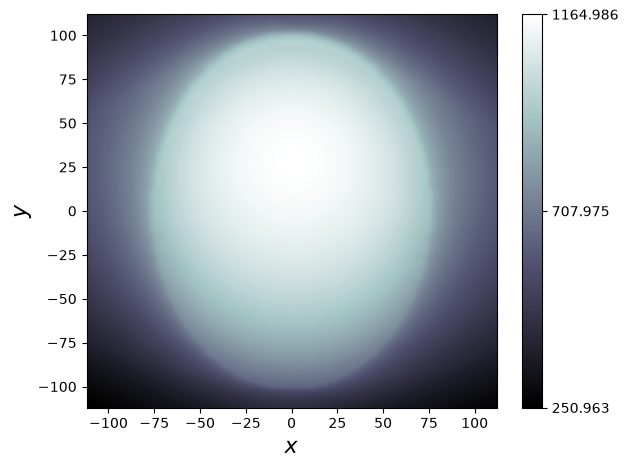

<Figure size 640x480 with 0 Axes>

Reconstitution :


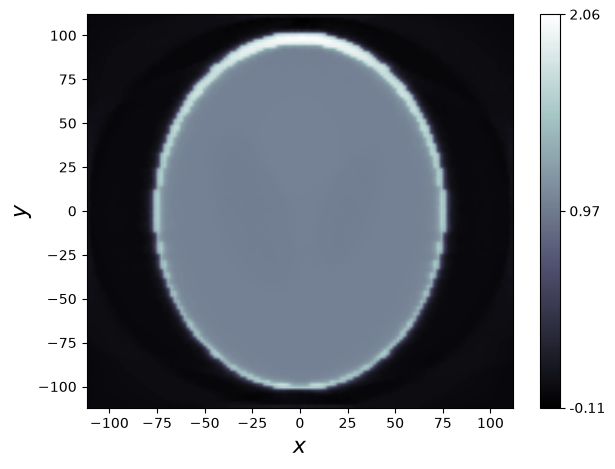

<Figure size 640x480 with 0 Axes>

In [17]:
solving_regularized_problem(reco_space, ray_trafo, data3d_shepp_logan, 1, 1/10**3, 1, 5, 30)
print("")

-> The reconstitution works on 3D data as well.

### Step 5.b - Reconstitution of the 3D CT

In [18]:
data_np = np.load("data/noisy_sinogram.npy")

print( data_np.shape)
print(data_space.shape)

(128, 780, 720)
(128, 780, 720)


The importation went well, the dimensions of each component are okay so I will transform the numpy array into an odl object

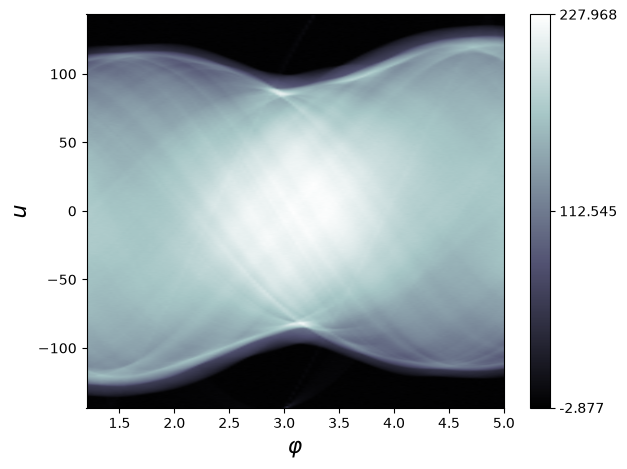

<Figure size 640x480 with 0 Axes>

In [19]:
data_3d_ct = data_space.element(data_np)
data_3d_ct.show()
print("")

f(point) = 2458250240.0
||gradient|| = 2414370.7267236253
f(point) = 1753384.28125
||gradient|| = 8425.159122188128
Naive reconstitution :


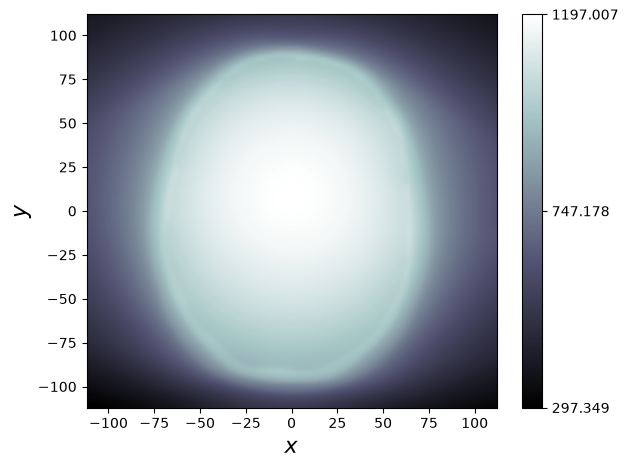

<Figure size 640x480 with 0 Axes>

Reconstitution :


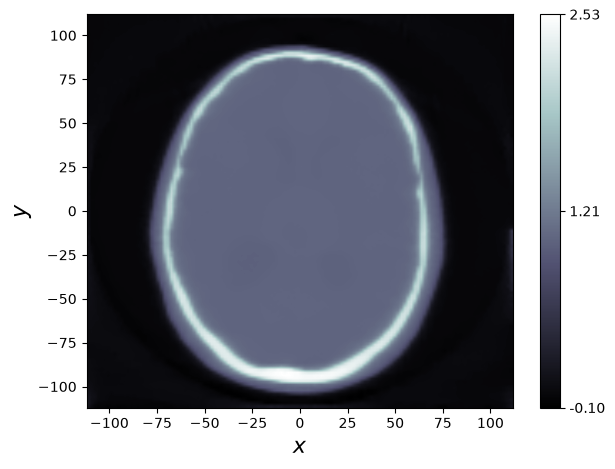

<Figure size 640x480 with 0 Axes>

In [20]:
reconstructed_3d_object_regularized = solving_regularized_problem(reco_space, ray_trafo, data_3d_ct, 1, 1/10**3, 1, 5, 30)
print("")

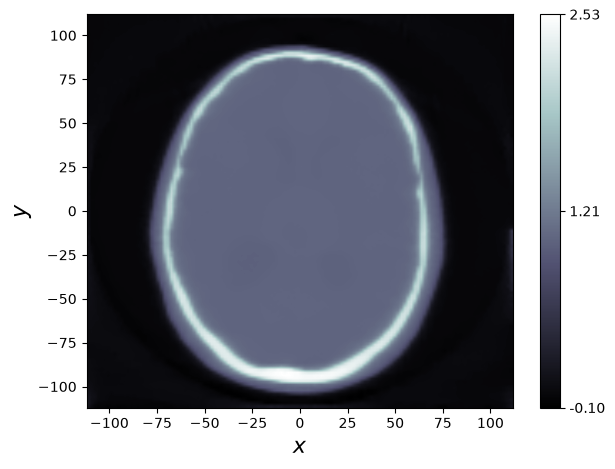

<Figure size 640x480 with 0 Axes>

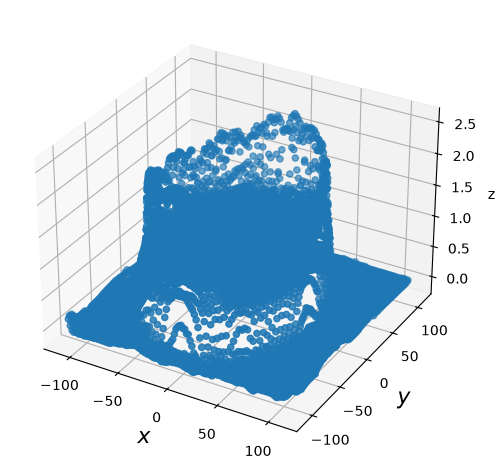

<Figure size 640x480 with 0 Axes>

In [21]:
reconstructed_3d_object_regularized.show()
reconstructed_3d_object_regularized.show(method="scatter")
print("")

The function executed well. The reconstituted image seems to be a head CT scan.
Below I will try using various lambda and showing the reconstitued image at each iteration.

In [22]:
def solving_regularized_problem_v3(space, forward, data, l, epsilon, alpha, tolerance, k):

    l2 = odl.functionals.L2NormSquared(forward.range)
    data_fit = l2.translated(data)
    
    grad = odl.Gradient(space)
    Heps = odl.functionals.Huber(grad.range, epsilon)
    
    regularization = l * Heps * grad
    
    f = 0.5* data_fit*forward + regularization
    x = space.zero()

    # Reconstituted at each iteration
    def callback(xk):
        xk.show()

    # Create the linesearch object
    line_search = odl.solvers.BacktrackingLineSearch(f, alpha =alpha, max_num_iter=k)
    
    # Call the solver
    try :
        odl.solvers.steepest_descent(f, x, maxiter=k, tol=tolerance, line_search=line_search, callback = callback)
    except AssertionError :
        pass

    return x

#### Test on the number of iterations

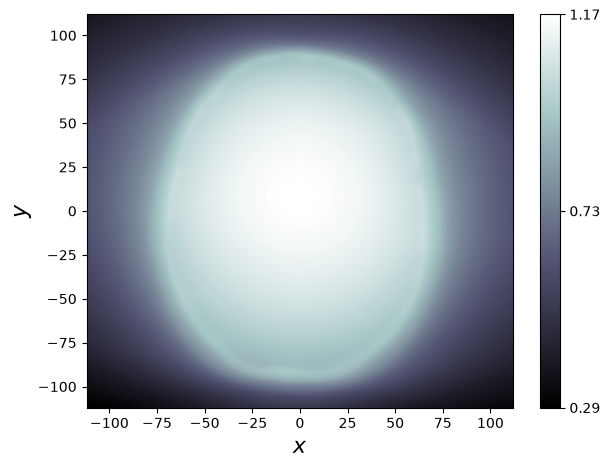

<Figure size 640x480 with 0 Axes>

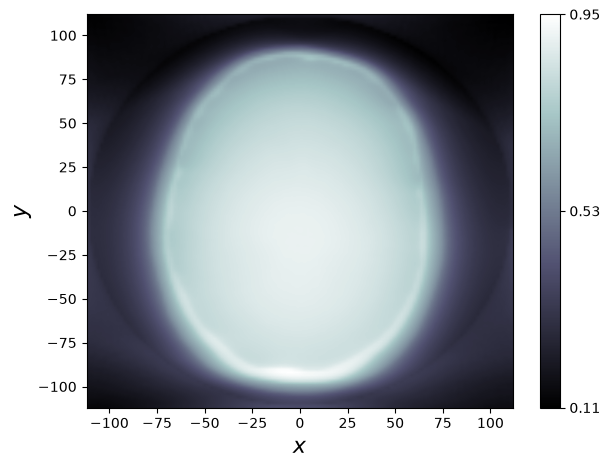

<Figure size 640x480 with 0 Axes>

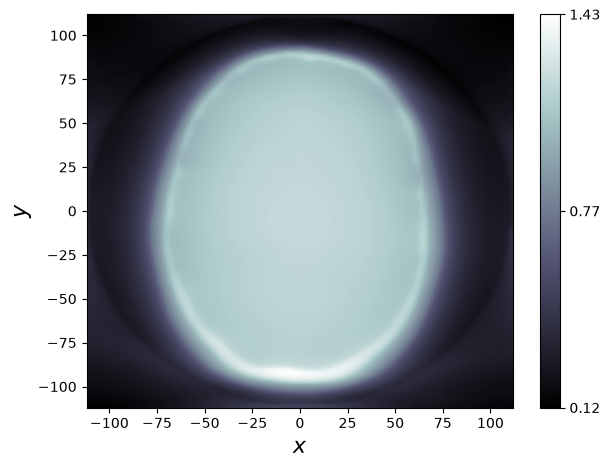

<Figure size 640x480 with 0 Axes>

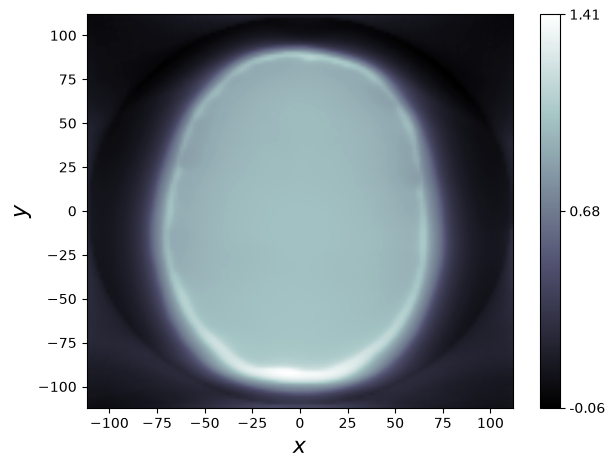

<Figure size 640x480 with 0 Axes>

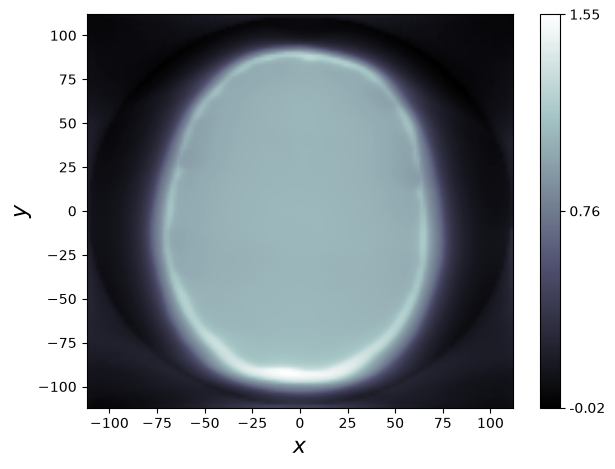

<Figure size 640x480 with 0 Axes>

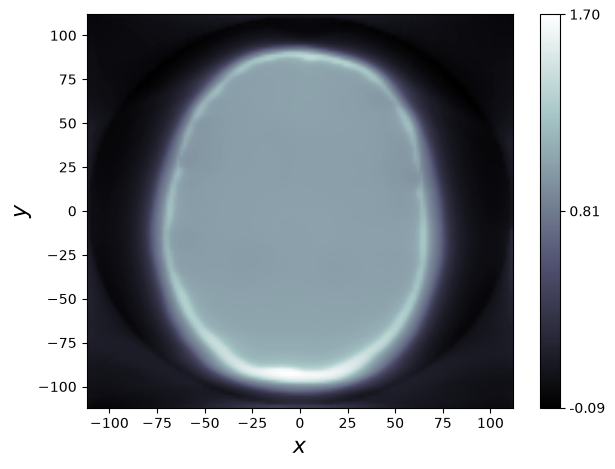

<Figure size 640x480 with 0 Axes>

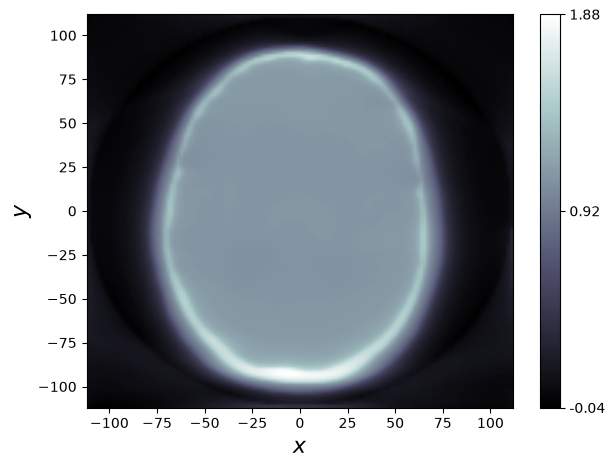

<Figure size 640x480 with 0 Axes>

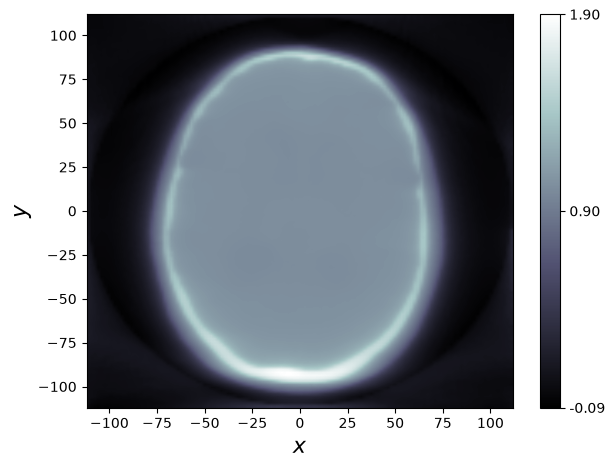

<Figure size 640x480 with 0 Axes>

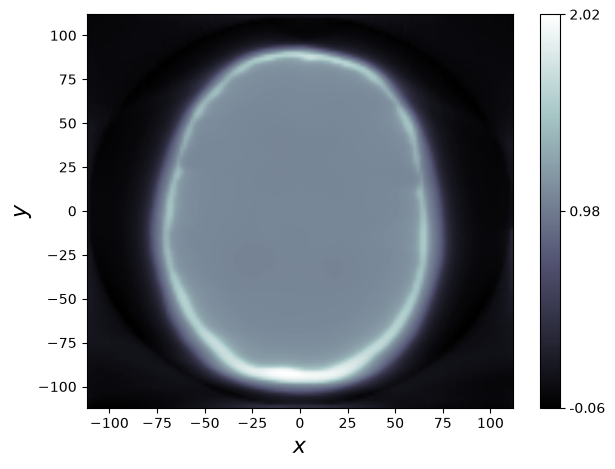

<Figure size 640x480 with 0 Axes>

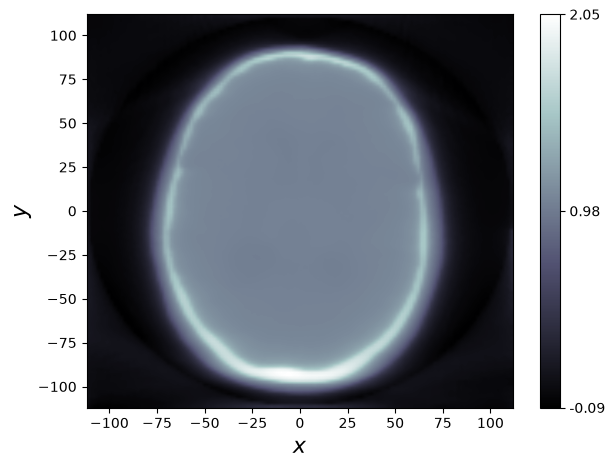

<Figure size 640x480 with 0 Axes>

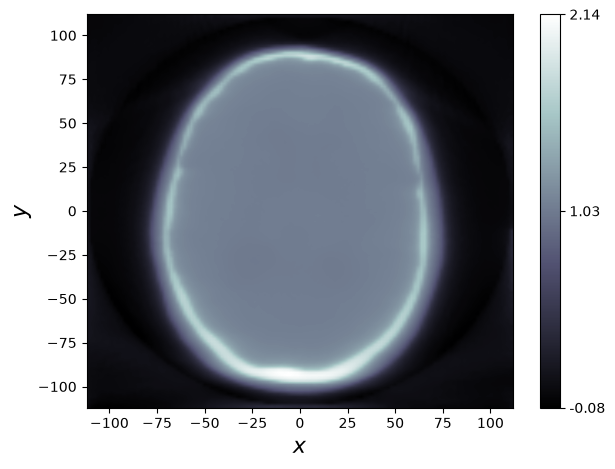

<Figure size 640x480 with 0 Axes>

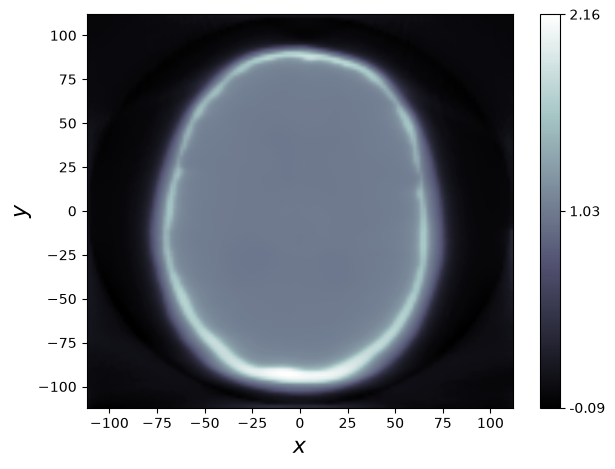

<Figure size 640x480 with 0 Axes>

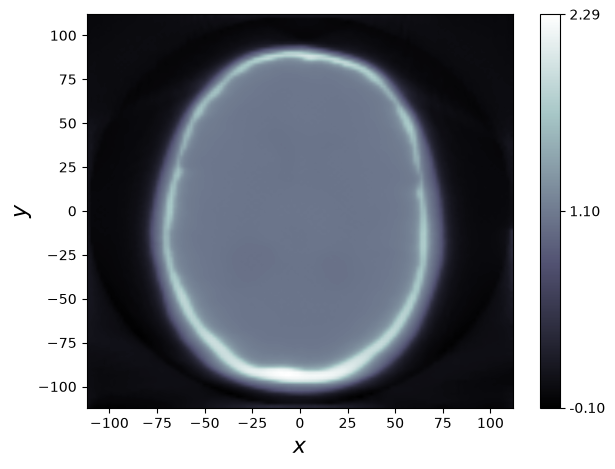

<Figure size 640x480 with 0 Axes>

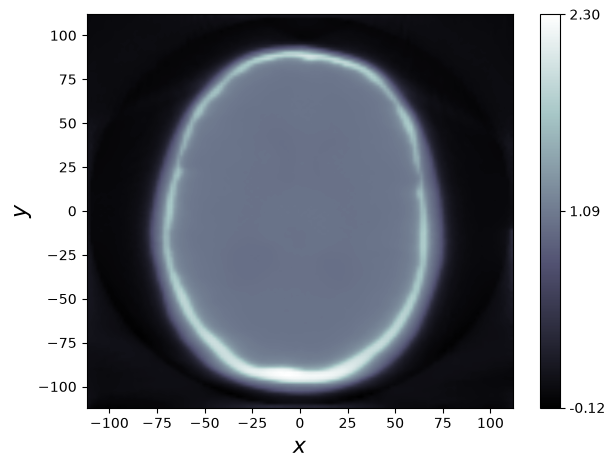

<Figure size 640x480 with 0 Axes>

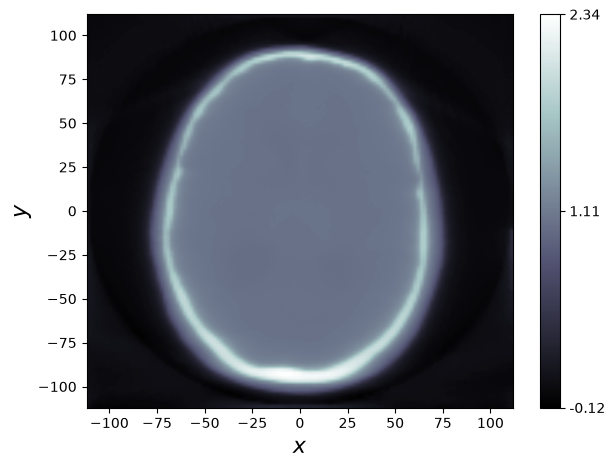

<Figure size 640x480 with 0 Axes>

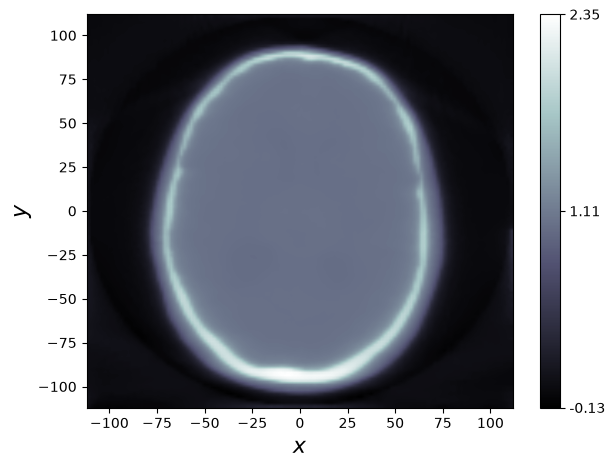

<Figure size 640x480 with 0 Axes>

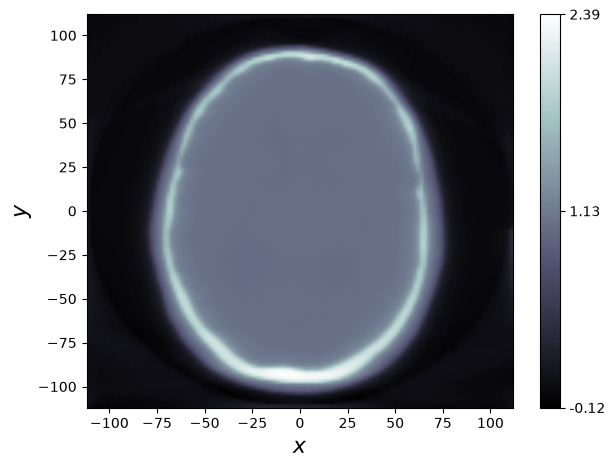

<Figure size 640x480 with 0 Axes>

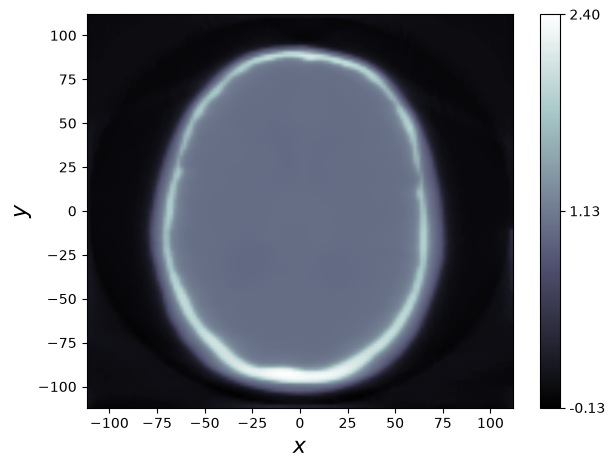

<Figure size 640x480 with 0 Axes>

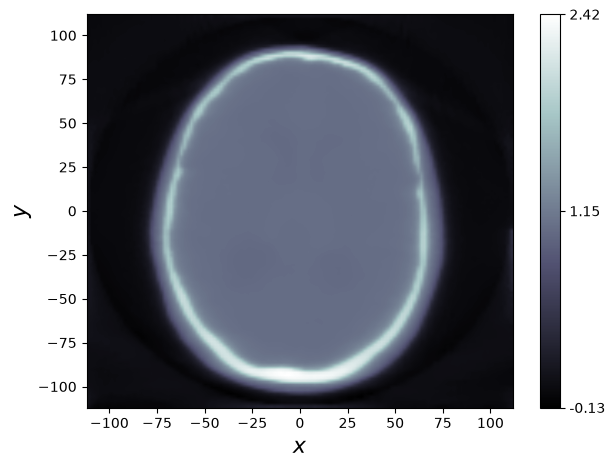

<Figure size 640x480 with 0 Axes>

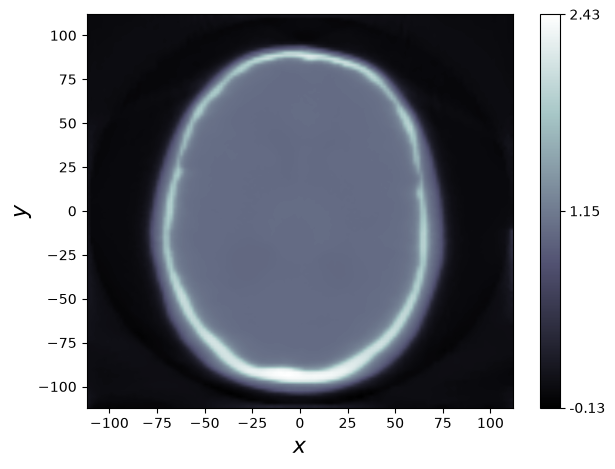

<Figure size 640x480 with 0 Axes>

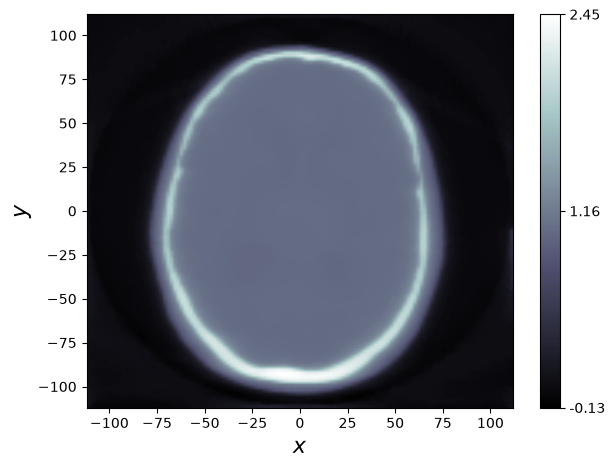

<Figure size 640x480 with 0 Axes>

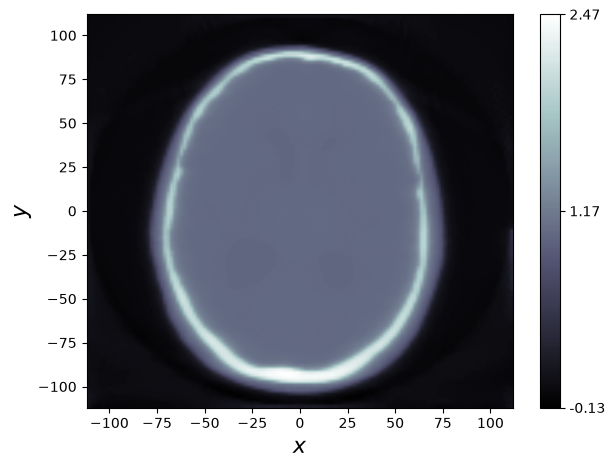

<Figure size 640x480 with 0 Axes>

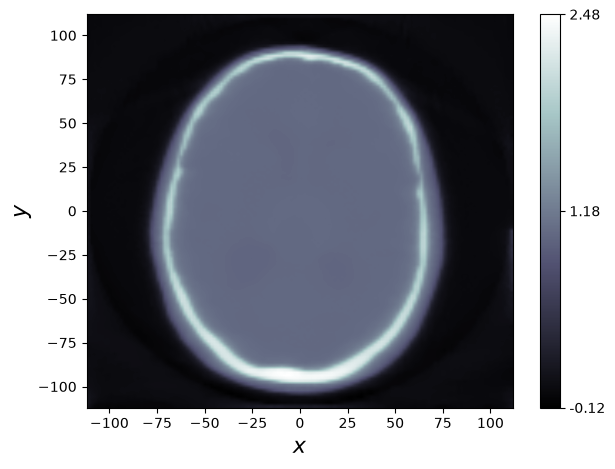

<Figure size 640x480 with 0 Axes>

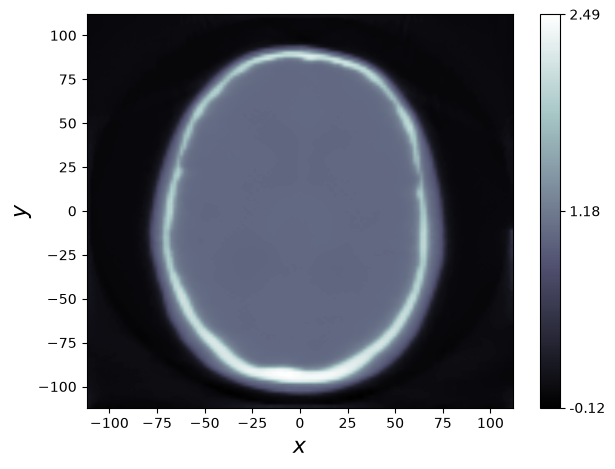

<Figure size 640x480 with 0 Axes>

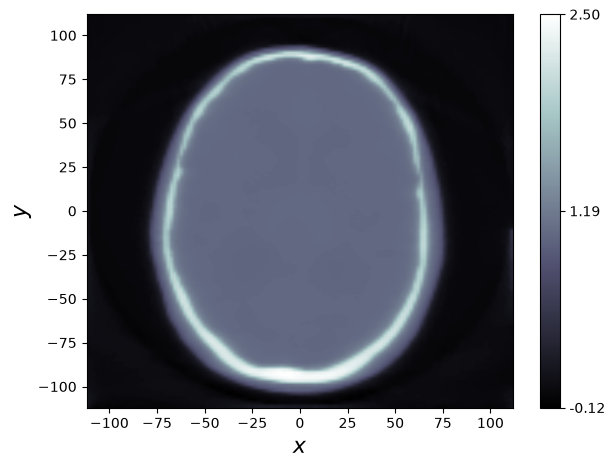

<Figure size 640x480 with 0 Axes>

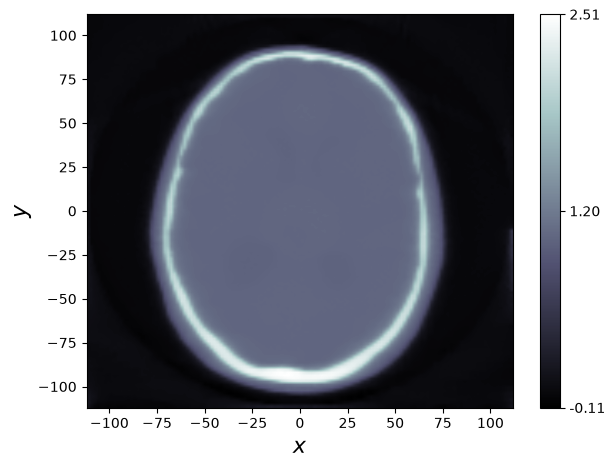

<Figure size 640x480 with 0 Axes>

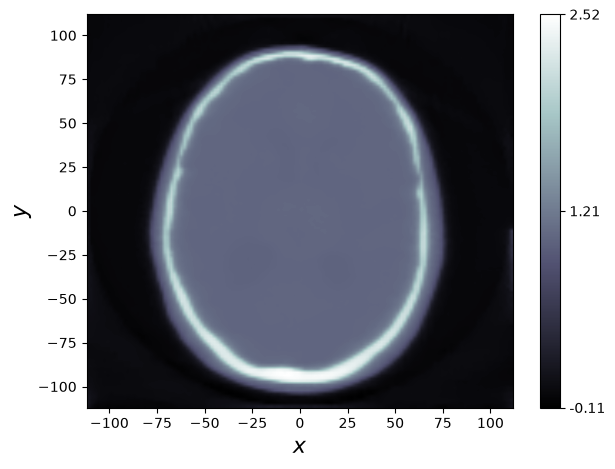

<Figure size 640x480 with 0 Axes>

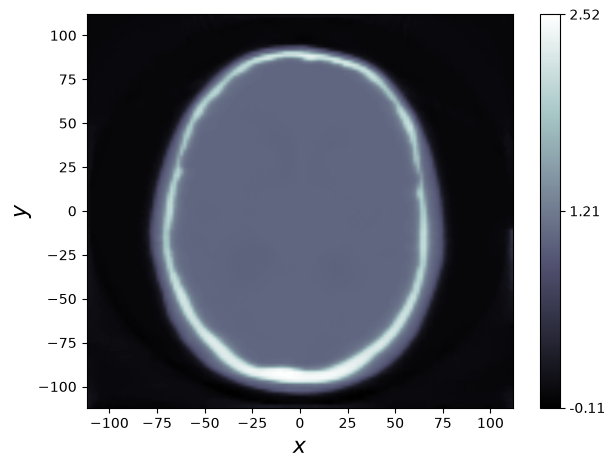

<Figure size 640x480 with 0 Axes>

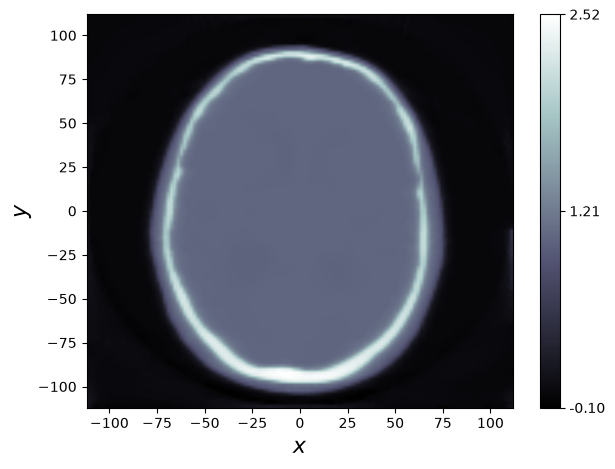

<Figure size 640x480 with 0 Axes>

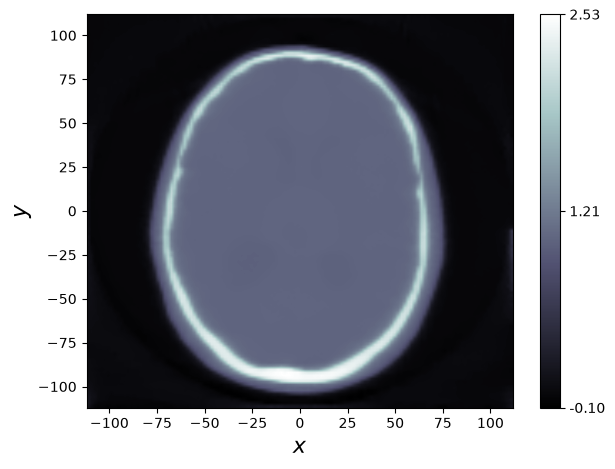

<Figure size 640x480 with 0 Axes>

In [23]:
solving_regularized_problem_v3(reco_space, ray_trafo, data_3d_ct, 1, 1/10**3, 1, 5, 30)
print("")

As the number of iterations goes up, the data are stabilizing.

#### Variation of the regularisation parameter

In [25]:
def solving_regularized_problem_v4(space, forward, data, l, epsilon, alpha, tolerance, k):

    l2 = odl.functionals.L2NormSquared(forward.range)
    data_fit = l2.translated(data)
    
    grad = odl.Gradient(space)
    Heps = odl.functionals.Huber(grad.range, epsilon)
    
    regularization = l * Heps * grad
    
    f = 0.5* data_fit*forward + regularization
    x = space.zero()

    # Evaluating the new functional in starting point.
    print("f(point) =", f(x))
    print("||gradient|| =", f.gradient(x).norm())

    # Create the linesearch object
    line_search = odl.solvers.BacktrackingLineSearch(f, alpha =alpha, max_num_iter=k)
    
    # Call the solver
    odl.solvers.steepest_descent(f, x, maxiter=k, tol=tolerance, line_search=line_search)

    # Evaluating the new functional in the point achieved.
    print("f(point) =", f(x))
    print("||gradient|| =", f.gradient(x).norm())

    print("Reconstitution :")
    x.show()    
    return x

Lambda = 10.0
f(point) = 2458250240.0
||gradient|| = 2414370.7267236253
f(point) = 6774185.0625
||gradient|| = 37458.36813795258
Reconstitution :


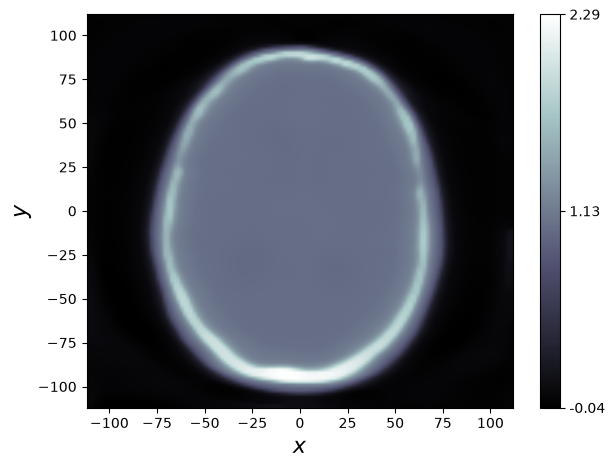

<Figure size 640x480 with 0 Axes>

Lambda = 1.0
f(point) = 2458250240.0
||gradient|| = 2414370.7267236253
f(point) = 1753384.28125
||gradient|| = 8425.159122188128
Reconstitution :


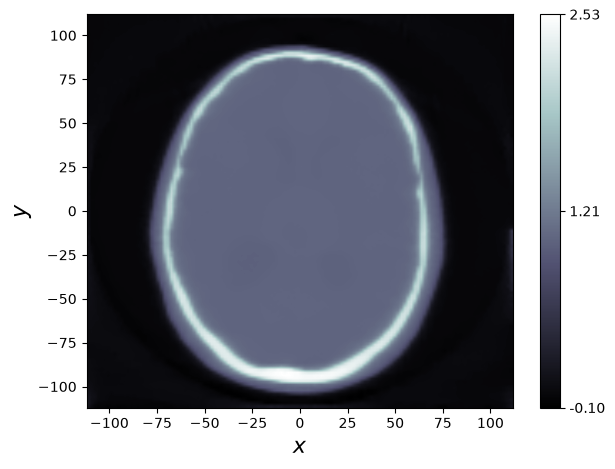

<Figure size 640x480 with 0 Axes>

Lambda = 0.1
f(point) = 2458250240.0
||gradient|| = 2414370.7267236253
f(point) = 1293872.75
||gradient|| = 16764.36814508324
Reconstitution :


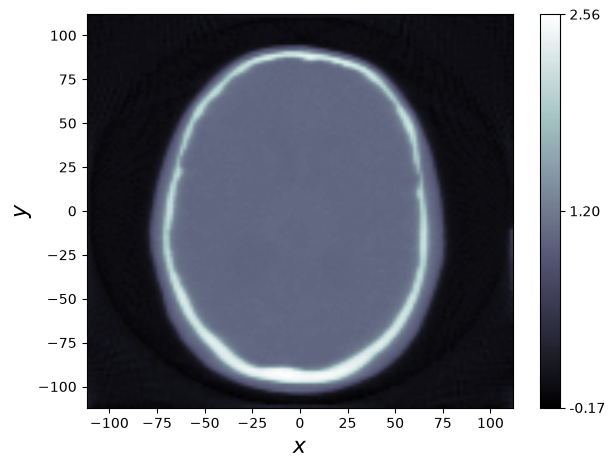

<Figure size 640x480 with 0 Axes>

Lambda = 0.01
f(point) = 2458250240.0
||gradient|| = 2414370.7267236253
f(point) = 1229148.74625
||gradient|| = 16777.360812257655
Reconstitution :


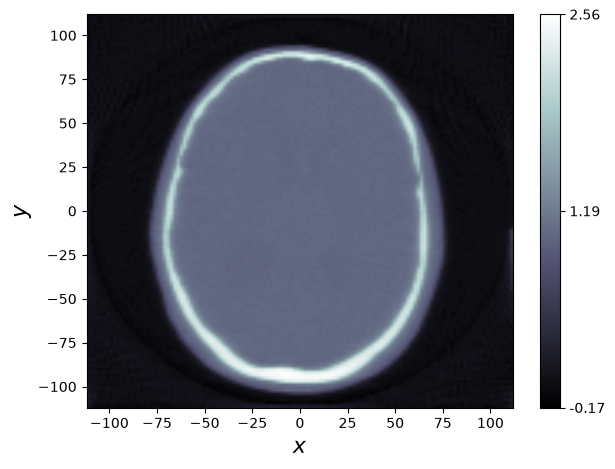

<Figure size 640x480 with 0 Axes>

Lambda = 0.001
f(point) = 2458250240.0
||gradient|| = 2414370.7267236253
f(point) = 1222284.1263125
||gradient|| = 16778.93544122703
Reconstitution :


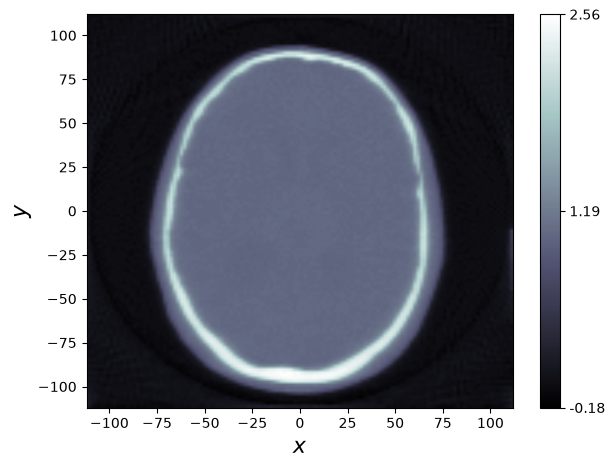

<Figure size 640x480 with 0 Axes>

In [26]:
lambdas = np.array([10, 1, 1/10**1, 1/10**2, 1/10**3])

for l in lambdas :
    print("Lambda =",l)
    solving_regularized_problem_v4(reco_space, ray_trafo, data_3d_ct, l, 1/10**3, 1, 5, 30)

print("")

In [27]:
def benchmark_lambda_without_phantom(space, data, forward, epsilon, tolerance, k, x1, x2, x3):

    lambdas = np.logspace(x1, x2, x3) #x3 points from 10**x1 to 10**x2
    
    l2 = odl.functionals.L2NormSquared(forward.range)
    data_fit = l2.translated(data)    
    grad = odl.Gradient(space)
    Heps = odl.functionals.Huber(grad.range, epsilon)
    
    residuals_list, penalties_list, errors_list = [], [], []
    x = space.zero()
    for l in lambdas:
        x = space.zero()
        l = float(l)
        regularization = l * Heps * grad
        f = 0.5 * data_fit * forward + regularization
    
        line_search = odl.solvers.BacktrackingLineSearch(f, alpha=1, max_num_iter=k)
        try:
            odl.solvers.steepest_descent(f, x, maxiter=k, line_search=line_search)
        except AssertionError:
            pass
    
        residuals_list.append(float((forward(x) - data).norm()))
        penalties_list.append(float(Heps(grad(x))))
        print(f"lambda={l:.1e}  residual={residuals_list[-1]:.3e}  H_eps={penalties_list[-1]:.3e} ")
        
    fig, ax = plt.subplots(figsize=(6, 4))
    
    ax.loglog(residuals_list, penalties_list, 'o-')
        
    for l, r, p in zip(lambdas, residuals_list, penalties_list):
        ax.annotate(f'{l:.0e}', (r, p), fontsize=7)

    ax.set(
        xlabel=r'$\|A x_\lambda - y\|$',
        ylabel=r'$H_\epsilon(\nabla x_\lambda)$',
        title='L curve'
    )
    
    plt.tight_layout()
    plt.show()

lambda=1.0e+01  residual=2.903e+03  H_eps=4.187e+05 
lambda=3.2e+00  residual=2.273e+03  H_eps=4.046e+05 
lambda=1.0e+00  residual=2.151e+03  H_eps=4.458e+05 
lambda=3.2e-01  residual=2.128e+03  H_eps=4.977e+05 
lambda=1.0e-01  residual=2.121e+03  H_eps=5.362e+05 
lambda=3.2e-02  residual=2.118e+03  H_eps=5.522e+05 
lambda=1.0e-02  residual=2.117e+03  H_eps=5.576e+05 
lambda=3.2e-03  residual=2.117e+03  H_eps=5.594e+05 
lambda=1.0e-03  residual=2.117e+03  H_eps=5.600e+05 


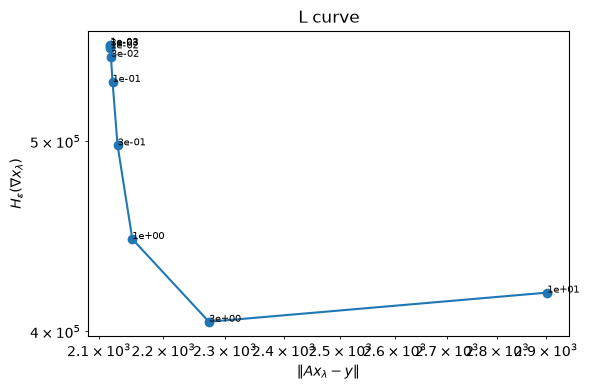

In [28]:
benchmark_lambda_without_phantom(reco_space, data_3d_ct, ray_trafo, 1/10**3, 5, 20, 1, -3, 9)

#### Some 2D slices of the initial reconstruction

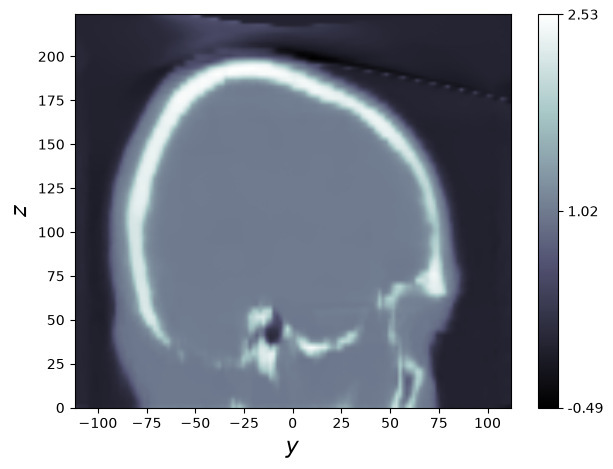

<Figure size 640x480 with 0 Axes>

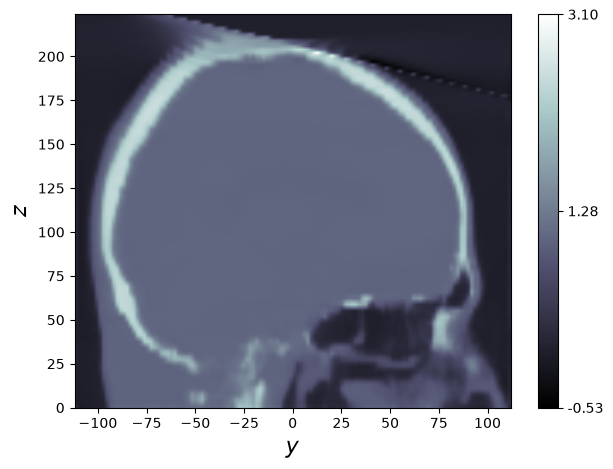

<Figure size 640x480 with 0 Axes>

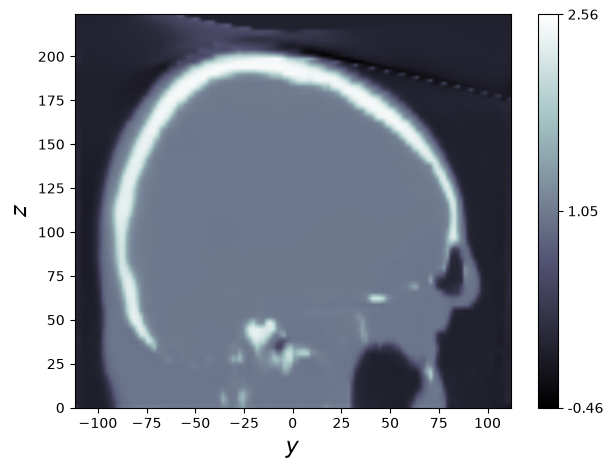

<Figure size 640x480 with 0 Axes>

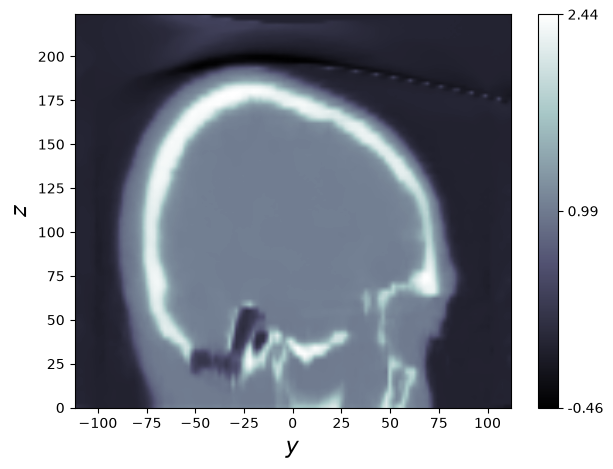

<Figure size 640x480 with 0 Axes>

In [29]:
reconstructed_3d_object_regularized.show(indices = 40)
reconstructed_3d_object_regularized.show(indices = 70)
reconstructed_3d_object_regularized.show(indices = 80)
reconstructed_3d_object_regularized.show(indices = 90)
print("")

## Step 6 - Reconstruction using Filtered Back-Projection

In [30]:
filter_ram_lak = odl.applications.tomo.analytic.filtered_back_projection.fbp_op(ray_trafo, filter_type='Ram-Lak')
filter_shepp_logan = odl.applications.tomo.analytic.filtered_back_projection.fbp_op(ray_trafo, filter_type='Shepp-Logan')
filter_cosine = odl.applications.tomo.analytic.filtered_back_projection.fbp_op(ray_trafo, filter_type='Cosine')
filter_hamming = odl.applications.tomo.analytic.filtered_back_projection.fbp_op(ray_trafo, filter_type='Hamming')
filter_hann = odl.applications.tomo.analytic.filtered_back_projection.fbp_op(ray_trafo, filter_type='Hann')

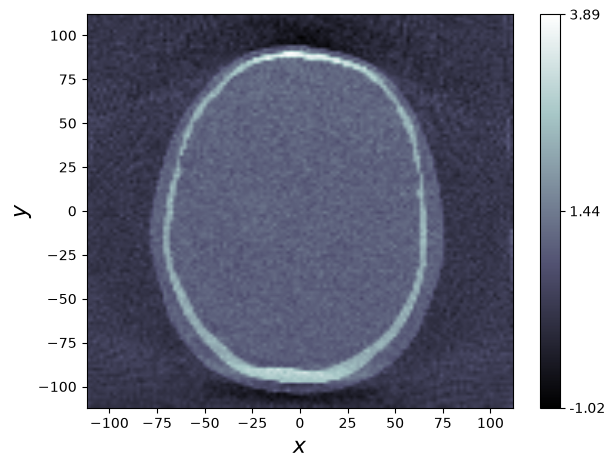

<Figure size 640x480 with 0 Axes>

In [31]:
filter_ram_lak(data_3d_ct).show()
print("")

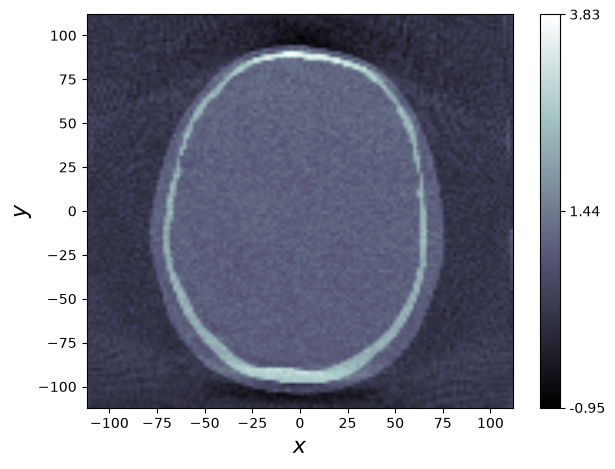

<Figure size 640x480 with 0 Axes>

In [32]:
filter_shepp_logan(data_3d_ct).show()
print("")

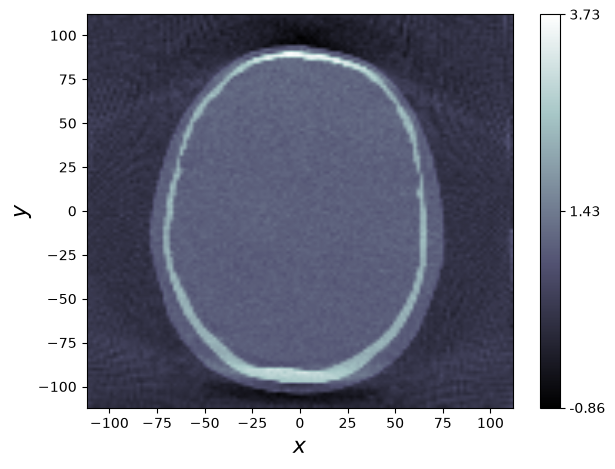

<Figure size 640x480 with 0 Axes>

In [33]:
filter_cosine(data_3d_ct).show()
print("")

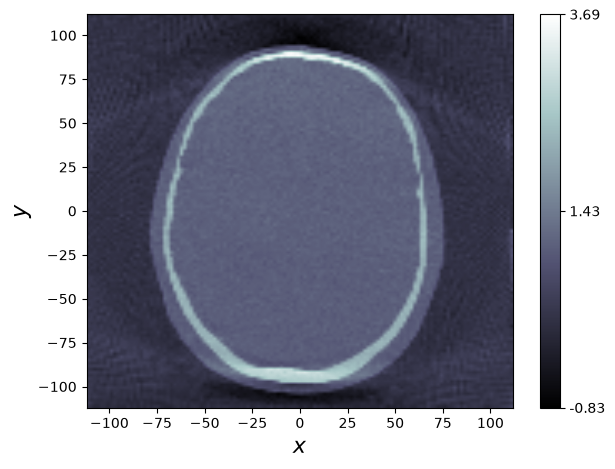

<Figure size 640x480 with 0 Axes>

In [34]:
filter_hamming(data_3d_ct).show()
print("")

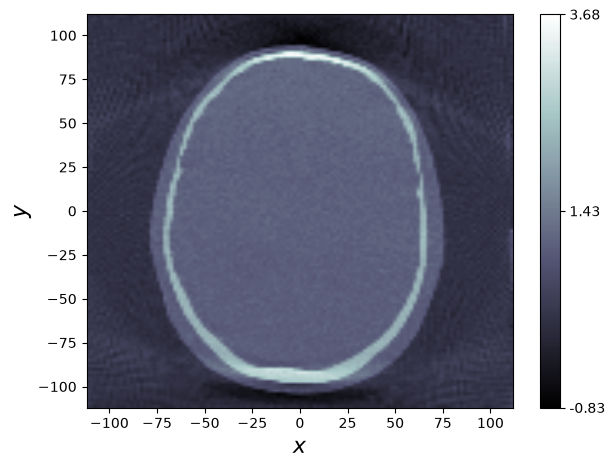

<Figure size 640x480 with 0 Axes>

In [35]:
filter_hann(data_3d_ct).show()
print("")

The filtered images are less blurry however noise is still present on them. We can also still see the ellipsoidal residual of the original data outside of the object. To reduce the noise, I will test different values of frequency_scaling.

In [36]:
filter_ram_lak_low_freq = odl.applications.tomo.analytic.filtered_back_projection.fbp_op(ray_trafo, filter_type='Ram-Lak', frequency_scaling=0.3)

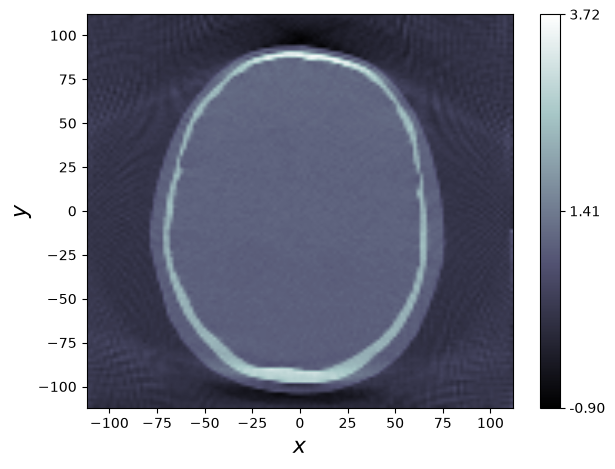

<Figure size 640x480 with 0 Axes>

In [37]:
filter_ram_lak_low_freq(data_3d_ct).show()
print("")

When lowering the frequency scaling of the Ram-Lak filter we have much less noise. The reconstitued image is less blurry than the one obtained by solving the regularized problem, however the little circles inside it still aren't visible in the filtered version.

In [38]:
filter_hann_low_freq = odl.applications.tomo.analytic.filtered_back_projection.fbp_op(ray_trafo, filter_type='Hann', frequency_scaling=0.3)

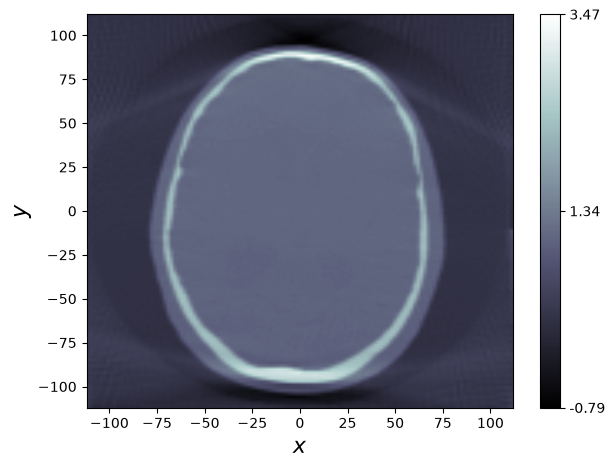

<Figure size 640x480 with 0 Axes>

In [39]:
filter_hann_low_freq(data_3d_ct).show()
print("")

When lowering the frequency scaling of the Hann filter the reconstituted image is much better. The little circles inside the object are a little bit visible.

In both cases we can still see the outline of the noise residuals outside of the object but given the fact that it doesn't perturb the visualization of the object I think that it could be fine.